In [1]:
#ASSUMPTIONS
S0 = 30
K = 30
r = 0.04
sigma = 0.15
T = 1
N =10000
M = 252        # Time steps
dt = 1/252
N_steps = int(T / dt)

In [2]:
green = "#70B761"
red = "#C85656"
grey = '#7f7f7f'
blue = "#2e7bb1"
black = "#363535"

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad

import os
# Create Plots folder if it doesn't exist
os.makedirs('report/Plots', exist_ok=True)

plt.rcParams['font.family'] = 'serif'
plt.style.use("seaborn-v0_8-deep")

green = "#70B761"
red = "#C85656"
rng = np.random.default_rng()
grey = '#7f7f7f'
blue = "#2e7bb1"
black = "#363535"
# === Payoff Functions ===
def absolute_payoff(S_T, K):
    return np.abs(S_T - K)

def quadratic_payoff(S_T, K):
    return (S_T - K)**2

# === Simulation Function ===
def simulate_GBM(S0, r, sigma, T, N, M, rng):
    dt = T / M
    Z = rng.standard_normal((N, M))
    log_returns = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    S = S0 * np.exp(np.cumsum(log_returns, axis=1))
    S = np.concatenate([np.full((N, 1), S0), S], axis=1)
    return S

from scipy.integrate import cumulative_trapezoid
# === Lognormal Density ===
def lognormal_density(s, S0, r, sigma, T):
    mu = np.log(S0) + (r - 0.5 * sigma**2) * T
    var = sigma**2 * T
    return 1 / (s * np.sqrt(2 * np.pi * var)) * np.exp(-(np.log(s) - mu)**2 / (2 * var))


# === Integrands ===
def integrand_abs(s, S0, K, r, sigma, T):
    return absolute_payoff(s, K) * lognormal_density(s, S0, r, sigma, T)

def integrand_quad(s, S0, K, r, sigma, T):
    return quadratic_payoff(s, K) * lognormal_density(s, S0, r, sigma, T)


def find_percentile(s_grid, cumsum, total, pct):
    idx = np.where(cumsum >= pct * total)[0]
    return s_grid[idx[0]] if len(idx) > 0 else s_grid[-1]

from scipy.integrate import quad
import numpy as np

def numerical_integration_table(S0, K, r, sigma, T):
    """
    Compute the numerical integration results for the absolute
    and quadratic payoff contracts.

    Returns
    -------
    results : dict
        Dictionary containing the integral, discounted price,
        and integration error for each payoff.
    """

    payoffs = {
        "Absolute": absolute_payoff,
        "Quadratic": quadratic_payoff,
    }

    print("=" * 78)
    print(f"{'Option':<12} {'Integral I':>18} {'Price V0':>18} {'Error':>18}")
    print("=" * 78)

    results = {}

    for name, payoff in payoffs.items():

        def integrand(s):
            return payoff(s, K) * lognormal_density(s, S0, r, sigma, T)

        I, err = quad(
            integrand,
            0,
            np.inf,
            epsrel=1e-10
        )

        V0 = np.exp(-r * T) * I

        results[name] = {
            "Integral": I,
            "Price": V0,
            "Error": err,
        }

        print(
            f"{name:<12}"
            f"{I:>18.8f}"
            f"{V0:>18.8f}"
            f"{err:>18.2e}"
        )

    print("=" * 78)

    return results

# === Black-Scholes Prices ===
def black_scholes_call(S0, K, r, sigma, T):
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def black_scholes_put(S0, K, r, sigma, T):
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


# Black-Scholes pricing functions
def black_scholes_price(S0, K, T, r, sigma, payoff_type='absolute'):
    """
    Calculate option price using Black-Scholes formula for absolute and quadratic payoffs
    """
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    
    if payoff_type == 'absolute':
        # Price of |S_T - K| = Call + Put
        call_price = S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
        put_price = K * np.exp(-r * T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)
        return call_price + put_price
    
    elif payoff_type == 'quadratic':
        # Price of (S_T - K)^2
        E_ST = S0 * np.exp(r * T)
        E_ST2 = S0**2 * np.exp(2 * r * T + sigma**2 * T)
        return E_ST2 - 2 * K * E_ST + K**2
    
    return 0

# Function to compute prices for a range of parameters
def compute_prices(param_values, param_name, fixed_params):
    prices_abs = []
    prices_quad = []
    
    for val in param_values:
        params = fixed_params.copy()
        params[param_name] = val
        
        price_abs = black_scholes_price(
            params['S0'], params['K'], params['T'], 
            params['r'], params['sigma'], 'absolute'
        )
        price_quad = black_scholes_price(
            params['S0'], params['K'], params['T'], 
            params['r'], params['sigma'], 'quadratic'
        )
        
        prices_abs.append(price_abs)
        prices_quad.append(price_quad)
    
    return np.array(prices_abs), np.array(prices_quad)


# Function to create 3-panel plots for each parameter
def create_parameter_plot(param_values, prices_abs, prices_quad, param_name, param_label, fixed_value):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    
    # Plot 1: Comparison (both together)
    ax = axes[0]
    ax.plot(param_values, prices_abs, color=green, linewidth=2.5, label='Absolute Payoff')
    ax.plot(param_values, prices_quad, color=blue, linewidth=2.5, label='Quadratic Payoff')
    ax.axvline(fixed_value, color='gray', linestyle='--', alpha=0.5, label=f'{param_name} = {fixed_value:.2f}')
    ax.set_xlabel(param_label, fontsize=12)
    ax.set_ylabel('Option Price', fontsize=12)
    ax.set_title('Comparison', fontsize=17, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    
    # Plot 2: Absolute Payoff only
    ax = axes[1]
    ax.plot(param_values, prices_abs, color=green, linewidth=3)
    ax.axvline(fixed_value, color='gray', linestyle='--', alpha=0.5, label=f'{param_name} = {fixed_value:.2f}')
    ax.set_xlabel(param_label, fontsize=12)
    ax.set_ylabel('Option Price', fontsize=12)
    ax.set_title('Absolute Payoff', fontsize=17, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    
    # Plot 3: Quadratic Payoff only
    ax = axes[2]
    ax.plot(param_values, prices_quad, color=blue, linewidth=3)
    ax.axvline(fixed_value, color='gray', linestyle='--', alpha=0.5, label=f'{param_name} = {fixed_value:.2f}')
    ax.set_xlabel(param_label, fontsize=12)
    ax.set_ylabel('Option Price', fontsize=12)
    ax.set_title('Quadratic Payoff', fontsize=17, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    return fig

# === Delta Functions ===
def delta_abs(S, K, r, sigma, T, t=0):
    tau = T - t
    if tau <= 0:
        return np.sign(S - K)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    return 2 * norm.cdf(d1) - 1

def delta_quad(S, K, r, sigma, T, t=0):
    tau = T - t
    if tau <= 0:
        return 2 * (S - K)
    return 2 * S * np.exp((r + sigma**2) * tau) - 2 * K 

def price_abs(S, K, r, sigma, tau):
    """Price of absolute payoff."""
    if tau <= 0:
        return np.abs(S - K)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)
    call = S * norm.cdf(d1) - K * np.exp(-r * tau) * norm.cdf(d2)
    put = K * np.exp(-r * tau) * norm.cdf(-d2) - S * norm.cdf(-d1)
    return call + put

def price_quad(S, K, r, sigma, tau):
    """Price of quadratic payoff."""
    if tau <= 0:
        return (S - K)**2
    return np.exp(-r * tau) * (S**2 * np.exp((2*r + sigma**2) * tau) - 2*K*S*np.exp(r * tau) + K**2)




def delta_call(S, K, r, sigma, tau):
    """Delta of call option."""
    if tau <= 0:
        return 1.0 * (S > K)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    return norm.cdf(d1)







# === Simulate one GBM path ===
def simulate_one_path(S0, r, sigma, T, dt):
    N = int(T / dt)
    path = np.zeros(N + 1)
    path[0] = S0
    for i in range(N):
        Z = np.random.standard_normal()
        path[i+1] = path[i] * np.exp((r - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z)
    return path


def delta_hedge_abs(S_path, K, r, sigma, T, dt):
    """Delta hedging for absolute payoff with portfolio delta tracking."""
    N = len(S_path) - 1
    t = np.linspace(0, T, N+1)
    tau = T - t
    
    V = np.zeros(N+1)
    delta_option = np.zeros(N+1)
    cash = np.zeros(N+1)
    shares = np.zeros(N+1)
    portfolio = np.zeros(N+1)
    port_delta_before = np.zeros(N+1)
    port_delta_after = np.zeros(N+1)
    
    V[0] = price_abs(S_path[0], K, r, sigma, T)
    delta_option[0] = delta_abs(S_path[0], K, r, sigma, T)
    shares[0] = delta_option[0]
    cash[0] = V[0] - delta_option[0] * S_path[0]
    portfolio[0] = V[0]
    port_delta_before[0] = 0
    port_delta_after[0] = 0
    
    for i in range(N):
        tau_next = tau[i+1]
        S_next = S_path[i+1]
        delta_new = delta_abs(S_next, K, r, sigma, tau_next)
        V_new = price_abs(S_next, K, r, sigma, tau_next)
        
        port_delta_before[i+1] = -delta_new + shares[i]
        shares_change = delta_new - shares[i]
        cash_new = cash[i] * np.exp(r * dt) - shares_change * S_next
        portfolio_after = delta_new * S_next + cash_new
        port_delta_after[i+1] = 0  # Always 0 after rebalancing
        
        shares[i+1] = delta_new
        cash[i+1] = cash_new
        portfolio[i+1] = portfolio_after
        V[i+1] = V_new
        delta_option[i+1] = delta_new
    
    return t, S_path, V, portfolio, delta_option, cash, shares, port_delta_before, port_delta_after
def delta_hedge_quad(S_path, K, r, sigma, T, dt):
    """Delta hedging for quadratic payoff with portfolio delta tracking."""
    N = len(S_path) - 1
    t = np.linspace(0, T, N+1)
    tau = T - t
    
    V = np.zeros(N+1)
    delta_option = np.zeros(N+1)
    cash = np.zeros(N+1)
    shares = np.zeros(N+1)
    portfolio = np.zeros(N+1)
    port_delta_before = np.zeros(N+1)
    port_delta_after = np.zeros(N+1)
    
    V[0] = price_quad(S_path[0], K, r, sigma, T)
    delta_option[0] = delta_quad(S_path[0], K, r, sigma, T)
    shares[0] = delta_option[0]
    cash[0] = V[0] - delta_option[0] * S_path[0]
    portfolio[0] = V[0]
    port_delta_before[0] = 0
    port_delta_after[0] = 0
    
    for i in range(N):
        tau_next = tau[i+1]
        S_next = S_path[i+1]
        delta_new = delta_quad(S_next, K, r, sigma, tau_next)
        V_new = price_quad(S_next, K, r, sigma, tau_next)
        
        # Portfolio delta BEFORE rebalancing (drifts away from 0)
        port_delta_before[i+1] = -delta_new + shares[i]
        
        # Rebalance
        shares_change = delta_new - shares[i]
        cash_new = cash[i] * np.exp(r * dt) - shares_change * S_next
        portfolio_after = delta_new * S_next + cash_new
        
        # Portfolio delta AFTER rebalancing (always 0)
        port_delta_after[i+1] = 0
        
        shares[i+1] = delta_new
        cash[i+1] = cash_new
        portfolio[i+1] = portfolio_after
        V[i+1] = V_new
        delta_option[i+1] = delta_new
    
    return t, S_path, V, portfolio, delta_option, cash, shares, port_delta_before, port_delta_after

# === Delta Hedging with Transaction Costs ===
def delta_hedge_abs_TC(S_path, K, r, sigma, T, dt, trans_cost=0.0):
    N = len(S_path) - 1
    t = np.linspace(0, T, N+1)
    tau = T - t
    
    V = np.zeros(N+1)
    delta_option = np.zeros(N+1)
    cash = np.zeros(N+1)
    shares = np.zeros(N+1)
    portfolio = np.zeros(N+1)
    
    V[0] = price_abs(S_path[0], K, r, sigma, T)
    delta_option[0] = delta_abs(S_path[0], K, r, sigma, T)
    shares[0] = delta_option[0]
    cash[0] = V[0] - delta_option[0] * S_path[0]
    portfolio[0] = V[0]
    
    for i in range(N):
        tau_next = tau[i+1]
        S_next = S_path[i+1]
        
        delta_new = delta_abs(S_next, K, r, sigma, tau_next)
        V_new = price_abs(S_next, K, r, sigma, tau_next)
        
        shares_change = delta_new - shares[i]
        cost = trans_cost * np.abs(shares_change * S_next) if trans_cost > 0 else 0.0
        cash_new = cash[i] * np.exp(r * dt) - shares_change * S_next - cost
        portfolio_after = delta_new * S_next + cash_new
        
        shares[i+1] = delta_new
        cash[i+1] = cash_new
        portfolio[i+1] = portfolio_after
        V[i+1] = V_new
        delta_option[i+1] = delta_new
    
    return t, V, portfolio, cash, shares, delta_option



def delta_hedge_quad_TC(S_path, K, r, sigma, T, dt, trans_cost=0.0):
    N = len(S_path) - 1
    t = np.linspace(0, T, N+1)
    tau = T - t
    
    V = np.zeros(N+1)
    delta_option = np.zeros(N+1)
    cash = np.zeros(N+1)
    shares = np.zeros(N+1)
    portfolio = np.zeros(N+1)
    
    V[0] = price_quad(S_path[0], K, r, sigma, T)
    delta_option[0] = delta_quad(S_path[0], K, r, sigma, T)
    shares[0] = delta_option[0]
    cash[0] = V[0] - delta_option[0] * S_path[0]
    portfolio[0] = V[0]
    
    for i in range(N):
        tau_next = tau[i+1]
        S_next = S_path[i+1]
        
        delta_new = delta_quad(S_next, K, r, sigma, tau_next)
        V_new = price_quad(S_next, K, r, sigma, tau_next)
        
        shares_change = delta_new - shares[i]
        cost = trans_cost * np.abs(shares_change * S_next) if trans_cost > 0 else 0.0
        cash_new = cash[i] * np.exp(r * dt) - shares_change * S_next - cost
        portfolio_after = delta_new * S_next + cash_new
        
        shares[i+1] = delta_new
        cash[i+1] = cash_new
        portfolio[i+1] = portfolio_after
        V[i+1] = V_new
        delta_option[i+1] = delta_new
    
    return t, V, portfolio, cash, shares, delta_option

# === Call Option Pricing and Greeks ===
def price_call(S, K_call, r, sigma, tau):
    """Black-Scholes Call price."""
    if tau <= 0:
        return np.maximum(S - K_call, 0)
    d1 = (np.log(S / K_call) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)
    return S * norm.cdf(d1) - K_call * np.exp(-r * tau) * norm.cdf(d2)

def gamma_call(S, K_call, r, sigma, tau):
    """Gamma of Call option."""
    if tau <= 0:
        return 0.0
    d1 = (np.log(S / K_call) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    return norm.pdf(d1) / (S * sigma * np.sqrt(tau))

def vega_call(S, K_call, r, sigma, tau):
    """Vega of Call option."""
    if tau <= 0:
        return 0.0
    d1 = (np.log(S / K_call) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    return S * np.sqrt(tau) * norm.pdf(d1)

# === Gamma of Quadratic Payoff ===
def gamma_quad(S, K, r, sigma, tau):
    """Gamma of quadratic payoff."""
    if tau <= 0:
        return 2.0
    # Gamma of quadratic = 2 * exp(-r*tau) * exp((2r+sigma^2)*tau) = 2 * exp((r+sigma^2)*tau)
    return 2 * np.exp((r + sigma**2) * tau)

# === Delta Hedging with Call Option for Gamma Hedge (FIXED) ===
def hedge_with_call(S_path, K, K_call, r, sigma, T, dt, trans_cost=0.0):
    """Hedge quadratic payoff with delta + call option (gamma hedge)."""
    N = len(S_path) - 1
    t = np.linspace(0, T, N+1)
    tau = T - t
    
    V = np.zeros(N+1)
    delta_quad_arr = np.zeros(N+1)
    gamma_quad_arr = np.zeros(N+1)
    
    call_price = np.zeros(N+1)
    call_delta = np.zeros(N+1)
    call_gamma = np.zeros(N+1)
    call_shares = np.zeros(N+1)
    
    shares = np.zeros(N+1)
    cash = np.zeros(N+1)
    portfolio = np.zeros(N+1)
    
    # Initial
    V[0] = price_quad(S_path[0], K, r, sigma, T)
    delta_quad_arr[0] = delta_quad(S_path[0], K, r, sigma, T)
    gamma_quad_arr[0] = gamma_quad(S_path[0], K, r, sigma, T)
    
    call_price[0] = price_call(S_path[0], K_call, r, sigma, T)
    call_delta[0] = delta_call(S_path[0], K_call, r, sigma, T)
    call_gamma[0] = gamma_call(S_path[0], K_call, r, sigma, T)
    
    # === FIX: Bound the call gamma to avoid division by zero ===
    min_gamma = 1e-8
    call_gamma_adj = max(call_gamma[0], min_gamma)
    
    # Number of calls = -Gamma_quad / Gamma_call (capped to avoid explosion)
    call_shares[0] = max(-50, min(50, -gamma_quad_arr[0] / call_gamma_adj))
    
    shares[0] = delta_quad_arr[0] + call_shares[0] * call_delta[0]
    cash[0] = V[0] - shares[0] * S_path[0] - call_shares[0] * call_price[0]
    portfolio[0] = V[0]
    
    for i in range(N):
        tau_next = tau[i+1]
        S_next = S_path[i+1]
        
        V_new = price_quad(S_next, K, r, sigma, tau_next)
        delta_new = delta_quad(S_next, K, r, sigma, tau_next)
        gamma_new = gamma_quad(S_next, K, r, sigma, tau_next)
        
        call_price_new = price_call(S_next, K_call, r, sigma, tau_next)
        call_delta_new = delta_call(S_next, K_call, r, sigma, tau_next)
        call_gamma_new = gamma_call(S_next, K_call, r, sigma, tau_next)
        
        # === FIX: Bound gamma ===
        call_gamma_adj = max(call_gamma_new, min_gamma)
        
        # New call position (gamma hedge) - CAPPED
        call_shares_new = max(-50, min(50, -gamma_new / call_gamma_adj))
        
        shares_new = delta_new + call_shares_new * call_delta_new
        
        shares_change = shares_new - shares[i]
        call_change = call_shares_new - call_shares[i]
        
        cost = trans_cost * (np.abs(shares_change * S_next) + np.abs(call_change * call_price_new))
        
        cash_new = cash[i] * np.exp(r * dt) - shares_change * S_next - call_change * call_price_new - cost
        portfolio_new = shares_new * S_next + call_shares_new * call_price_new + cash_new
        
        V[i+1] = V_new
        delta_quad_arr[i+1] = delta_new
        gamma_quad_arr[i+1] = gamma_new
        call_price[i+1] = call_price_new
        call_delta[i+1] = call_delta_new
        call_gamma[i+1] = call_gamma_new
        call_shares[i+1] = call_shares_new
        shares[i+1] = shares_new
        cash[i+1] = cash_new
        portfolio[i+1] = portfolio_new
    
    error = V[-1] - portfolio[-1]
    
    return t, V, portfolio, error, shares, call_shares, cash

# === Compute errors with call hedge ===
def compute_errors_with_call(S0, K, K_call, r, sigma, T, dt, N_paths, trans_cost=0.0):
    errors = np.zeros(N_paths)
    
    for i in range(N_paths):
        S_path = simulate_one_path(S0, r, sigma, T, dt)
        _, _, _, error, _, _, _ = hedge_with_call(S_path, K, K_call, r, sigma, T, dt, trans_cost)
        
        # === FIX: Cap errors to avoid inf/nan ===
        if np.isnan(error) or np.isinf(error):
            error = 0.0
        errors[i] = max(-1e6, min(1e6, error))  # Cap at +/- 1e6
    
    return errors



# 1.1 Constuction

<>:8: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:13: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:8: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:13: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/var/folders/qr/j8df0yz964s42s7h8zvb7j_c0000gn/T/ipykernel_42847/892065918.py:8: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  plt.plot(S, payoff_abs, linewidth=3, color=green, label='$\psi_T^a = |S_T - K|$')
/var/folders/qr/j8df0yz964s42s7h8zvb7j_c0000gn/T/ipykernel_42847/892065918

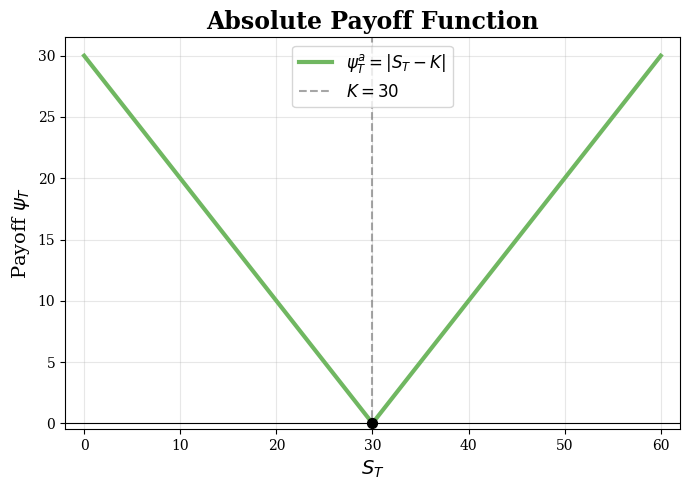

In [4]:
# === Absolute Payoff ===
S = np.linspace(0, 60, 2000)
K = 30

payoff_abs = np.maximum(S - K, 0) + np.maximum(K - S, 0)

plt.figure(figsize=(7,5))
plt.plot(S, payoff_abs, linewidth=3, color=green, label='$\psi_T^a = |S_T - K|$')
plt.axvline(K, linestyle='--', color='grey', alpha=0.7, label=f'$K = {K}$')
plt.axhline(0, color='black', linewidth=0.8)
plt.scatter([K], [0], color='black', zorder=5, s=50)
plt.xlabel('$S_T$', fontsize=14)
plt.ylabel('Payoff $\psi_T$', fontsize=14)
plt.title('Absolute Payoff Function', fontsize=17, fontweight='bold')
plt.legend(loc='upper center', fontsize=12)
plt.grid(True, alpha=0.3)
plt.xlim(-2, 62)
plt.ylim(-0.5, payoff_abs.max() * 1.05)
plt.tight_layout()
plt.savefig('report/Plots/Absolut_Payoff.pdf', bbox_inches='tight', dpi=300)
plt.show()

<>:38: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:38: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/var/folders/qr/j8df0yz964s42s7h8zvb7j_c0000gn/T/ipykernel_42847/3830784004.py:38: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  plt.ylabel('Payoff $\psi_T$', fontsize=14)


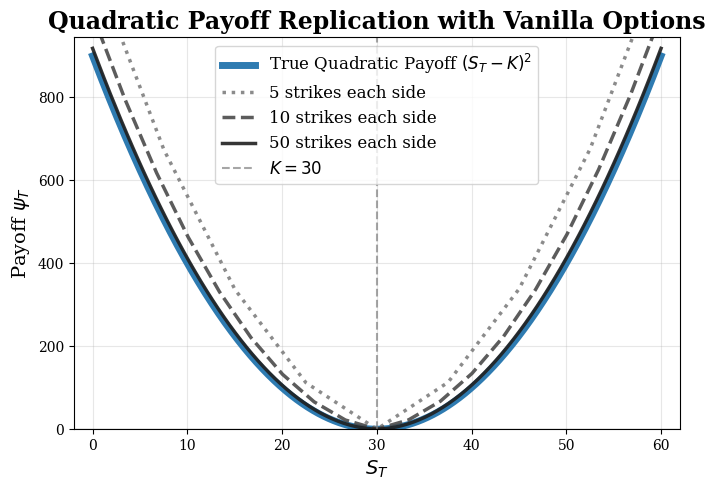

In [5]:
# === Quadratic Payoff Replication ===
target = (S - K)**2

def quadratic_replication_calls_puts(S, K, n_strikes, K_min=0, K_max=60):
    K_puts = np.linspace(K_min, K, n_strikes)
    K_calls = np.linspace(K, K_max, n_strikes)

    dK_put = K_puts[1] - K_puts[0]
    dK_call = K_calls[1] - K_calls[0]

    payoff = np.zeros_like(S)

    for k in K_puts:
        payoff += dK_put * np.maximum(k - S, 0)

    for k in K_calls:
        payoff += dK_call * np.maximum(S - k, 0)

    return 2 * payoff

plt.figure(figsize=(7, 5))

# True quadratic payoff
plt.plot(S, target, color=blue, linewidth=5, label='True Quadratic Payoff $(S_T - K)^2$')

# Approximations
linestyles = [':', '--', '-']
colors = [grey, '#4a4a4a', '#1f1f1f']
for i, n in enumerate([5, 10, 50]):
    approx = quadratic_replication_calls_puts(S, K, n)
    plt.plot(S, approx, linewidth=2.5, alpha=0.9, 
             label=f'{n} strikes each side', 
             color=colors[i], linestyle=linestyles[i])

plt.axvline(K, linestyle='--', color='grey', alpha=0.7, label=f'$K = {K}$')
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('$S_T$', fontsize=14)
plt.ylabel('Payoff $\psi_T$', fontsize=14)
plt.title('Quadratic Payoff Replication with Vanilla Options', fontsize=17, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper center', fontsize=12)
plt.xlim(-2, 62)
plt.ylim(-0.5, target.max() * 1.05)
plt.tight_layout()
plt.savefig('report/Plots/Quadratic_payoff.pdf', bbox_inches='tight', dpi=300)
plt.show()

# 1.2

<>:16: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:16: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/var/folders/qr/j8df0yz964s42s7h8zvb7j_c0000gn/T/ipykernel_42847/3850654373.py:16: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  plt.ylabel('Payoff $\psi_T$', fontsize=14)


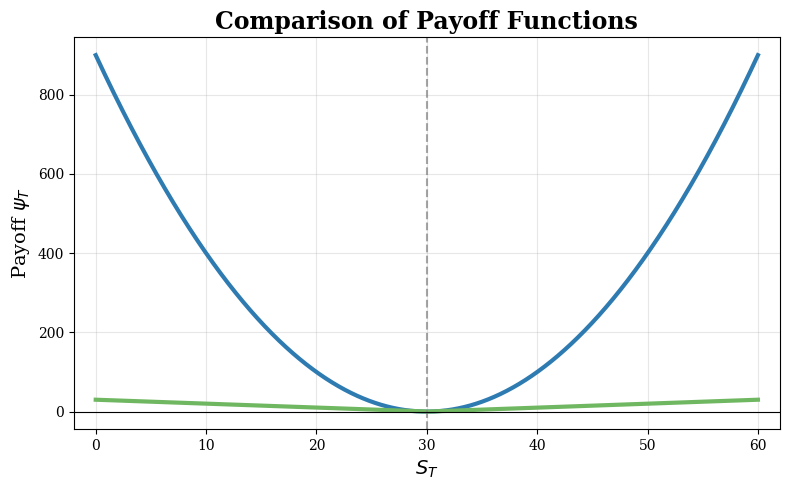

In [6]:
# === Comparison: Absolute vs Quadratic Payoffs ===
S = np.linspace(0, 60, 2000)
K = 30

payoff_abs = np.maximum(S - K, 0) + np.maximum(K - S, 0)
payoff_quad = (S - K)**2

plt.figure(figsize=(8, 5))

plt.plot(S, payoff_quad, color=blue, linewidth=3, label='Quadratic Payoff $(S_T - K)^2$')
plt.plot(S, payoff_abs, color=green, linewidth=3, label='Absolute Payoff $|S_T - K|$')

plt.axvline(K, linestyle='--', color='grey', alpha=0.7, label=f'$K = {K}$')
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('$S_T$', fontsize=14)
plt.ylabel('Payoff $\psi_T$', fontsize=14)
plt.title('Comparison of Payoff Functions', fontsize=17, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xlim(-2, 62)
#plt.ylim(-60, max(payoff_abs.max(), payoff_quad.max()) * 1.05)
plt.tight_layout()
plt.savefig('report/Plots/Comparaison_Large.pdf', bbox_inches='tight', dpi=300)
plt.show()

<>:14: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:14: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/var/folders/qr/j8df0yz964s42s7h8zvb7j_c0000gn/T/ipykernel_42847/934228245.py:14: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  plt.ylabel('Payoff $\psi_T$', fontsize=14)


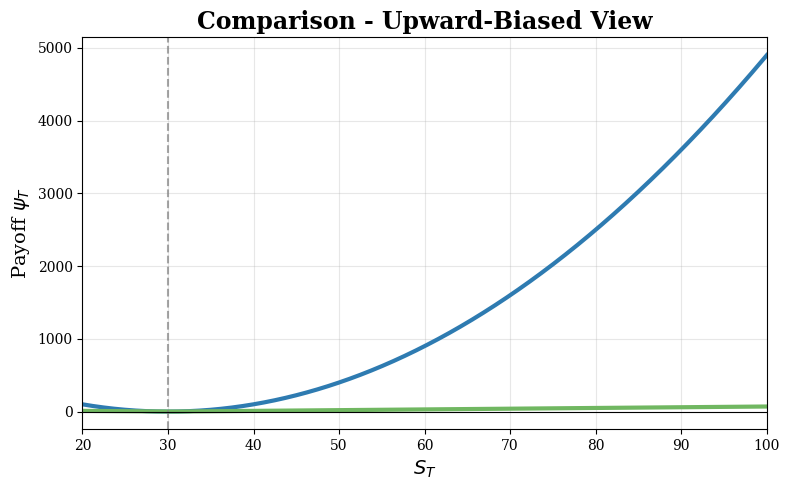

In [7]:
# === Upward-biased comparison (zoomed right tail) ===
plt.figure(figsize=(8, 5))
S_bias = np.linspace(0, 100, 2000)

payoff_abs_bias = np.maximum(S_bias - K, 0) + np.maximum(K - S_bias, 0)
payoff_quad_bias = (S_bias - K)**2

plt.plot(S_bias, payoff_quad_bias, color=blue, linewidth=3, label='Quadratic Payoff')
plt.plot(S_bias, payoff_abs_bias, color=green, linewidth=3, label='Absolute Payoff')

plt.axvline(K, linestyle='--', color='grey', alpha=0.7, label=f'$K = {K}$')
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('$S_T$', fontsize=14)
plt.ylabel('Payoff $\psi_T$', fontsize=14)
plt.title('Comparison - Upward-Biased View', fontsize=17, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xlim(20, 100)
#plt.ylim(-50, 1200)
plt.tight_layout()
plt.savefig('report/Plots/Comparaison_Right.pdf', bbox_inches='tight', dpi=300)
plt.show()


<>:10: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:10: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/var/folders/qr/j8df0yz964s42s7h8zvb7j_c0000gn/T/ipykernel_42847/3059780267.py:10: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  plt.ylabel('Payoff $\psi_T$', fontsize=14)


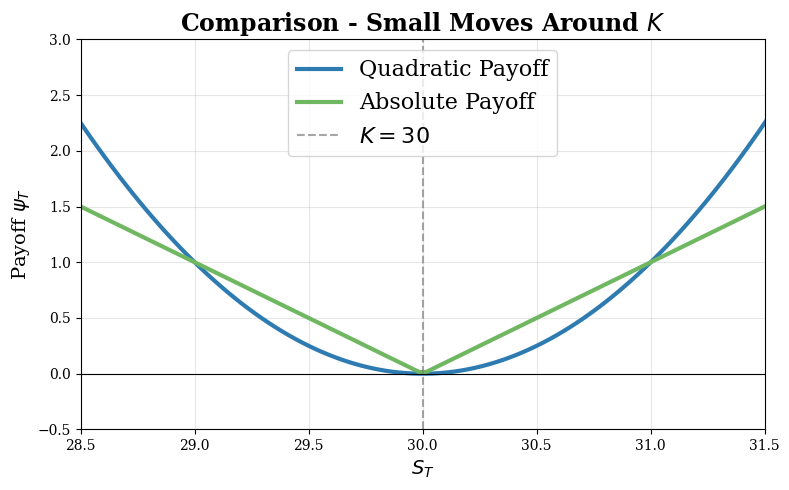

In [8]:
# === Small move comparison (zoomed around K) ===
plt.figure(figsize=(8, 5))

plt.plot(S, payoff_quad, color=blue, linewidth=3, label='Quadratic Payoff')
plt.plot(S, payoff_abs, color=green, linewidth=3, label='Absolute Payoff')

plt.axvline(K, linestyle='--', color='grey', alpha=0.7, label=f'$K = {K}$')
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('$S_T$', fontsize=14)
plt.ylabel('Payoff $\psi_T$', fontsize=14)
plt.title('Comparison - Small Moves Around $K$', fontsize=17, fontweight='bold')
plt.legend(loc='upper center', fontsize=16)
plt.grid(True, alpha=0.3)
plt.xlim(K - 1.5, K + 1.5)
plt.ylim(-0.5, 3)
plt.tight_layout()
plt.savefig('report/Plots/Comparaison_Small.pdf', bbox_inches='tight', dpi=300)
plt.show()

# 2.1 Monte Carlo 

In [9]:
N_values = np.logspace(2, 6, 8, dtype=int)


# === Generate paths for GBM plot ===
S_paths = simulate_GBM(S0, r, sigma, T, N, M, rng)
S_T = S_paths[:, -1]

# === Run Convergence Study ===
prices_abs, prices_quad = [], []
errors_abs, errors_quad = [], []

for n in N_values:
    # Simulate terminal prices
    Z = rng.standard_normal(n)
    S_T_n = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    
    # Absolute
    payoffs_abs = np.exp(-r * T) * absolute_payoff(S_T_n, K)
    prices_abs.append(np.mean(payoffs_abs))
    errors_abs.append(np.std(payoffs_abs) / np.sqrt(n))
    
    # Quadratic
    payoffs_quad = np.exp(-r * T) * quadratic_payoff(S_T_n, K)
    prices_quad.append(np.mean(payoffs_quad))
    errors_quad.append(np.std(payoffs_quad) / np.sqrt(n))

# === Reference Prices ===
N_ref = 10_000_000
Z_ref = rng.standard_normal(N_ref)
S_T_ref = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z_ref)
price_abs_ref = np.mean(np.exp(-r * T) * absolute_payoff(S_T_ref, K))
price_quad_ref = np.mean(np.exp(-r * T) * quadratic_payoff(S_T_ref, K))


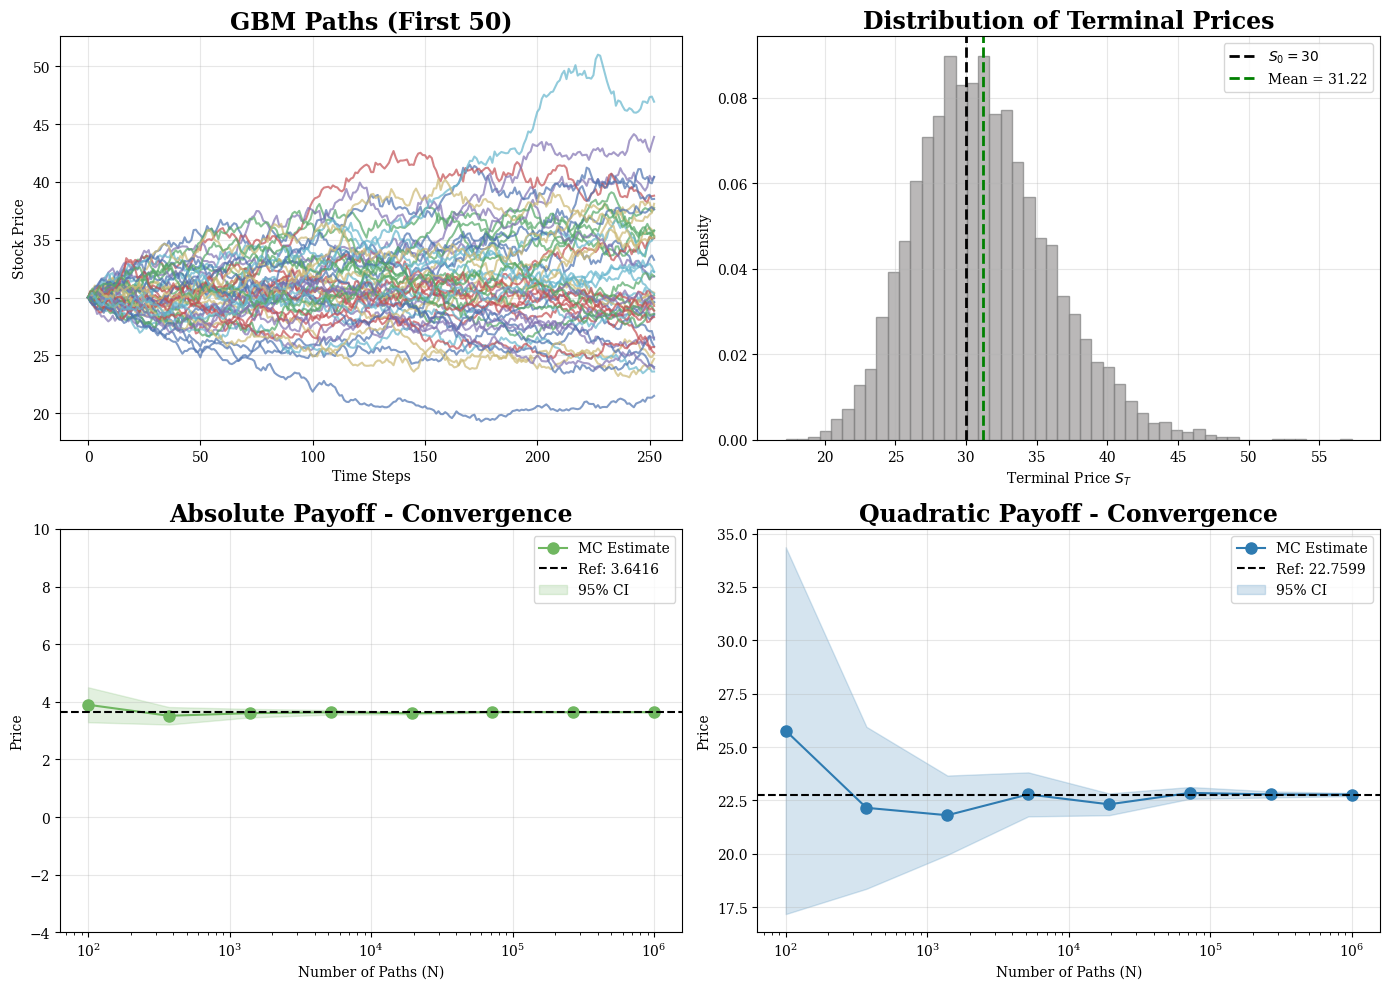

In [10]:


# === 2x2 Plot ===
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. GBM Paths (Top Left)
ax = axes[0, 0]
ax.plot(S_paths[:50, :].T, alpha=0.7)
ax.set_xlabel('Time Steps')
ax.set_ylabel('Stock Price')
ax.set_title('GBM Paths (First 50)',fontsize=17, fontweight='bold')
ax.grid(True, alpha=0.3)

# 2. Terminal Distribution (Top Right)
ax = axes[0, 1]
ax.hist(S_T, bins=50, density=True, alpha=0.7, color="#9D9A9A", edgecolor='grey')
ax.axvline(S0, color='k', linestyle='--', linewidth=2, label=f'$S_0 = {S0}$')
ax.axvline(np.mean(S_T), color='green', linestyle='--', linewidth=2, label=f'Mean = {np.mean(S_T):.2f}')
ax.set_xlabel('Terminal Price $S_T$')
ax.set_ylabel('Density')
ax.set_title('Distribution of Terminal Prices',fontsize=17, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# 3. Absolute Payoff Convergence (Bottom Left)
ax = axes[1, 0]
ax.semilogx(N_values, prices_abs, '-o', label='MC Estimate', color=green, markersize=8)
ax.axhline(price_abs_ref, color='k', linestyle='--', label=f'Ref: {price_abs_ref:.4f}')
ax.fill_between(N_values,
                 np.array(prices_abs) - 1.96*np.array(errors_abs),
                 np.array(prices_abs) + 1.96*np.array(errors_abs),
                 alpha=0.2, color=green, label='95% CI')
ax.set_xlabel('Number of Paths (N)')
ax.set_ylabel('Price')
ax.set_title('Absolute Payoff - Convergence',fontsize=17, fontweight='bold')
ax.set_ylim(-4,10)
ax.legend()
ax.grid(True, alpha=0.3)

# 4. Quadratic Payoff Convergence (Bottom Right)
ax = axes[1, 1]
ax.semilogx(N_values, prices_quad, '-o', label='MC Estimate', color=blue, markersize=8)
ax.axhline(price_quad_ref, color='k', linestyle='--', label=f'Ref: {price_quad_ref:.4f}')
ax.fill_between(N_values,
                 np.array(prices_quad) - 1.96*np.array(errors_quad),
                 np.array(prices_quad) + 1.96*np.array(errors_quad),
                 alpha=0.2, color=blue, label='95% CI')
ax.set_xlabel('Number of Paths (N)')
ax.set_ylabel('Price')
ax.set_title('Quadratic Payoff - Convergence',fontsize=17, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('report/Plots/Monte_Carlo.pdf', bbox_inches='tight', dpi=1000)
plt.show()



# 2.2 Numerical Integration 

<>:60: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:60: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/var/folders/qr/j8df0yz964s42s7h8zvb7j_c0000gn/T/ipykernel_42847/339152886.py:60: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  ax.set_title('Integrands $\psi(s) f_{S_T}(s)$', fontsize=17, fontweight='bold')


REFERENCE PRICES (Scipy Quad)
Absolute Payoff:  3.64084299
Quadratic Payoff: 22.75550826


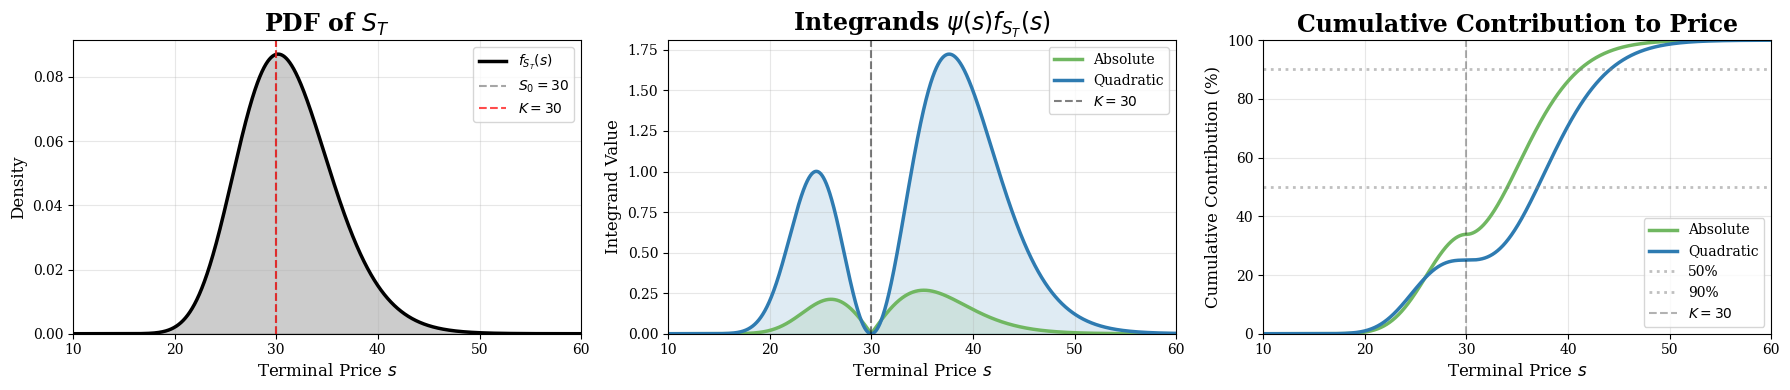


CONTRIBUTION ANALYSIS
     Percentile |    Absolute (s) |   Quadratic (s)
------------------------------------------------------------
            50% |           34.05 |           37.04
            75% |           37.76 |           40.70
            90% |           41.15 |           44.14
            95% |           43.30 |           46.34
            99% |           47.65 |           50.81


In [11]:

# === Grid for plotting ===
a, b = 0.01, 100
s_grid = np.linspace(a, b, 100000)

# === Compute density and integrands ===
f_s = lognormal_density(s_grid, S0, r, sigma, T)
integrand_abs_values = absolute_payoff(s_grid, K) * f_s
integrand_quad_values = quadratic_payoff(s_grid, K) * f_s

# === Cumulative sums ===
dx = s_grid[1] - s_grid[0]
#cumsum_abs = np.cumsum(integrand_abs_values) * dx
cumsum_abs = cumulative_trapezoid(integrand_abs_values,s_grid,initial=0)
#cumsum_quad = np.cumsum(integrand_quad_values) * dx
cumsum_quad = cumulative_trapezoid(integrand_quad_values,s_grid,initial=0)
total_abs = cumsum_abs[-1]
total_quad = cumsum_quad[-1]

# === Reference Prices ===
I_abs_ref, _ = quad(integrand_abs, 0, np.inf, args=(S0, K, r, sigma, T), epsrel=1e-10)
I_quad_ref, _ = quad(integrand_quad, 0, np.inf, args=(S0, K, r, sigma, T), epsrel=1e-10)
V_abs_ref = np.exp(-r * T) * I_abs_ref
V_quad_ref = np.exp(-r * T) * I_quad_ref

print("="*60)
print("REFERENCE PRICES (Scipy Quad)")
print("="*60)
print(f"Absolute Payoff:  {V_abs_ref:.8f}")
print(f"Quadratic Payoff: {V_quad_ref:.8f}")
print("="*60)

# ============================================================================
# CREATE 3 PLOTS
# ============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# --- Plot 1: Probability Density Function (PDF) of S_T ---
ax = axes[0]
ax.plot(s_grid, f_s, 'k-', linewidth=2.5, label='$f_{S_T}(s)$')
ax.axvline(S0, color='gray', linestyle='--', alpha=0.7, label=f'$S_0 = {S0}$')
ax.axvline(K, color='red', linestyle='--', alpha=0.7, label=f'$K = {K}$')
ax.fill_between(s_grid, f_s, alpha=0.2, color='black')
ax.set_xlabel('Terminal Price $s$', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.set_title('PDF of $S_T$', fontsize=17, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 60)
ax.set_ylim(bottom=0)

# --- Plot 2: Integrands ---
ax = axes[1]
ax.plot(s_grid, integrand_abs_values, color=green, linewidth=2.5, label='Absolute')
ax.plot(s_grid, integrand_quad_values, color=blue, linewidth=2.5, label='Quadratic')
ax.axvline(K, color='k', linestyle='--', alpha=0.5, label=f'$K = {K}$')
ax.fill_between(s_grid, integrand_abs_values, alpha=0.15, color=green)
ax.fill_between(s_grid, integrand_quad_values, alpha=0.15, color=blue)
ax.set_xlabel('Terminal Price $s$', fontsize=12)
ax.set_ylabel('Integrand Value', fontsize=12)
ax.set_title('Integrands $\psi(s) f_{S_T}(s)$', fontsize=17, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 60)
ax.set_ylim(bottom=0)

# --- Plot 3: Cumulative Contribution ---
ax = axes[2]
ax.plot(s_grid, cumsum_abs / total_abs * 100, color=green, linewidth=2.5, label='Absolute')
ax.plot(s_grid, cumsum_quad / total_quad * 100, color=blue, linewidth=2.5, label='Quadratic')
ax.axhline(50, color='gray', linestyle=':', alpha=0.5, linewidth=2, label='50%')
ax.axhline(90, color='gray', linestyle=':', alpha=0.5, linewidth=2, label='90%')
ax.axvline(K, color='k', linestyle='--', alpha=0.3, label=f'$K = {K}$')
ax.set_xlabel('Terminal Price $s$', fontsize=12)
ax.set_ylabel('Cumulative Contribution (%)', fontsize=12)
ax.set_title('Cumulative Contribution to Price', fontsize=17, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 60)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.savefig('report/Plots/numerical_integration_analysis.pdf', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================================
# PRINT CONTRIBUTION ANALYSIS
# ============================================================================


pct_levels = [0.5, 0.75, 0.9, 0.95, 0.99]
abs_levels = [find_percentile(s_grid, cumsum_abs, total_abs, p) for p in pct_levels]
quad_levels = [find_percentile(s_grid, cumsum_quad, total_quad, p) for p in pct_levels]

print("\n" + "="*60)
print("CONTRIBUTION ANALYSIS")
print("="*60)
print(f"{'Percentile':>15} | {'Absolute (s)':>15} | {'Quadratic (s)':>15}")
print("-"*60)
labels = ['50%', '75%', '90%', '95%', '99%']
for label, abs_val, quad_val in zip(labels, abs_levels, quad_levels):
    print(f"{label:>15} | {abs_val:>15.2f} | {quad_val:>15.2f}")
print("="*60)

In [12]:
results = numerical_integration_table(S0, K, r, sigma, T)

Option               Integral I           Price V0              Error
Absolute            3.78942861        3.64084299          7.44e-09
Quadratic          23.68417817       22.75550826          1.49e-08


# Put-call parity

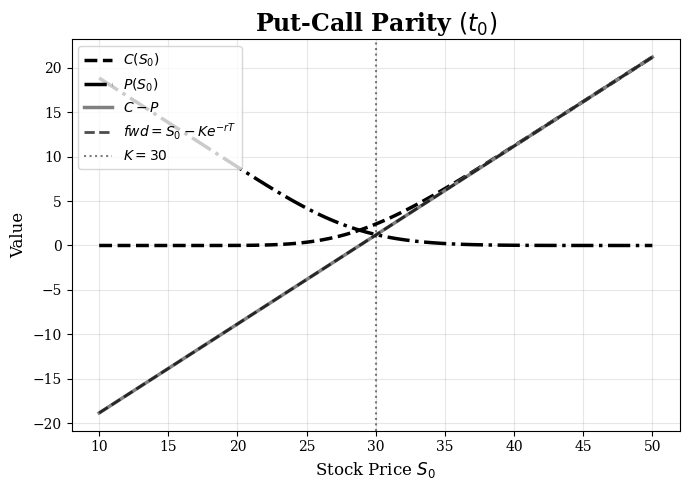

In [13]:
S_range = np.linspace(10, 50, 100)



# === Compute ===
call_prices = [black_scholes_call(S, K, r, sigma, T) for S in S_range]
put_prices = [black_scholes_put(S, K, r, sigma, T) for S in S_range]

# === Plot ===
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(S_range, call_prices, 'k--', linewidth=2.5, label='$C(S_0)$')
ax.plot(S_range, put_prices,'k-.', linewidth=2.5, label='$P(S_0)$')
ax.plot(S_range, np.array(call_prices) - np.array(put_prices), '-', color='grey',linewidth=2.5, label='$C - P$')
ax.plot(S_range, S_range - K * np.exp(-r * T), 'k--', linewidth=2, alpha=0.7, label='$fwd = S_0 - Ke^{-rT}$')
ax.axvline(K, color='k', linestyle=':', alpha=0.5, label=f'$K = {K}$')
ax.set_xlabel('Stock Price $S_0$', fontsize=12)
ax.set_ylabel('Value', fontsize=12)
ax.set_title(r'Put-Call Parity $(t_0)$', fontsize=17, fontweight='bold')
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('report/Plots/put_call_parity.pdf', dpi=300, bbox_inches='tight')
plt.show()

# 2.3 Parametre test ! 

/Users/babadesiles/Library/Mobile Documents/com~apple~CloudDocs/Basile_Learning/Master_1/Derivatives Pricing/Project/function.py:133: RuntimeWarning: divide by zero encountered in log
  d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
/Users/babadesiles/Library/Mobile Documents/com~apple~CloudDocs/Basile_Learning/Master_1/Derivatives Pricing/Project/function.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))


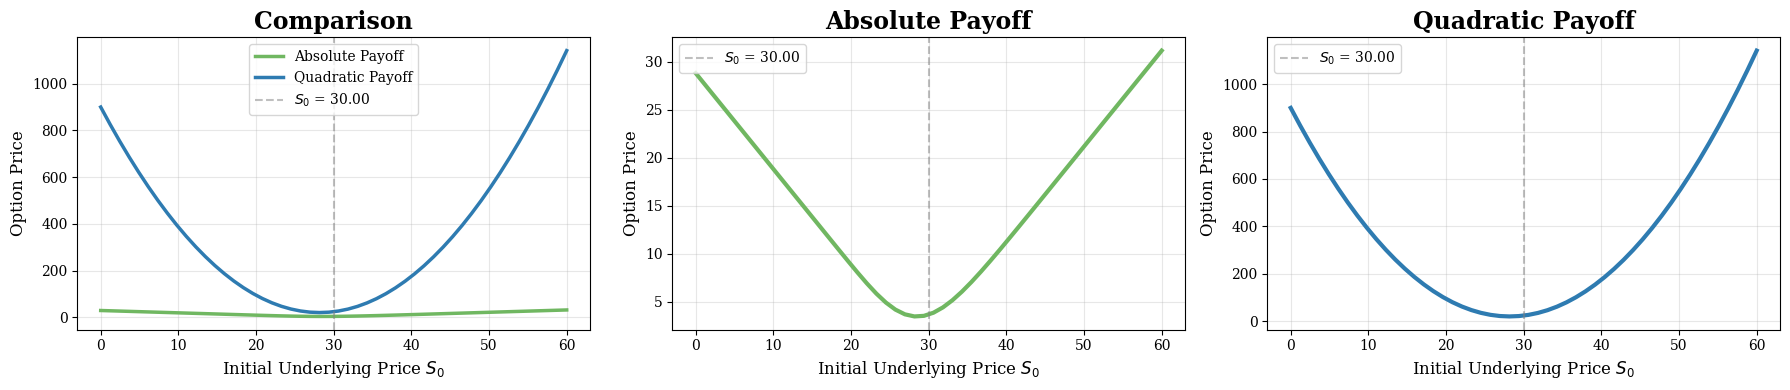

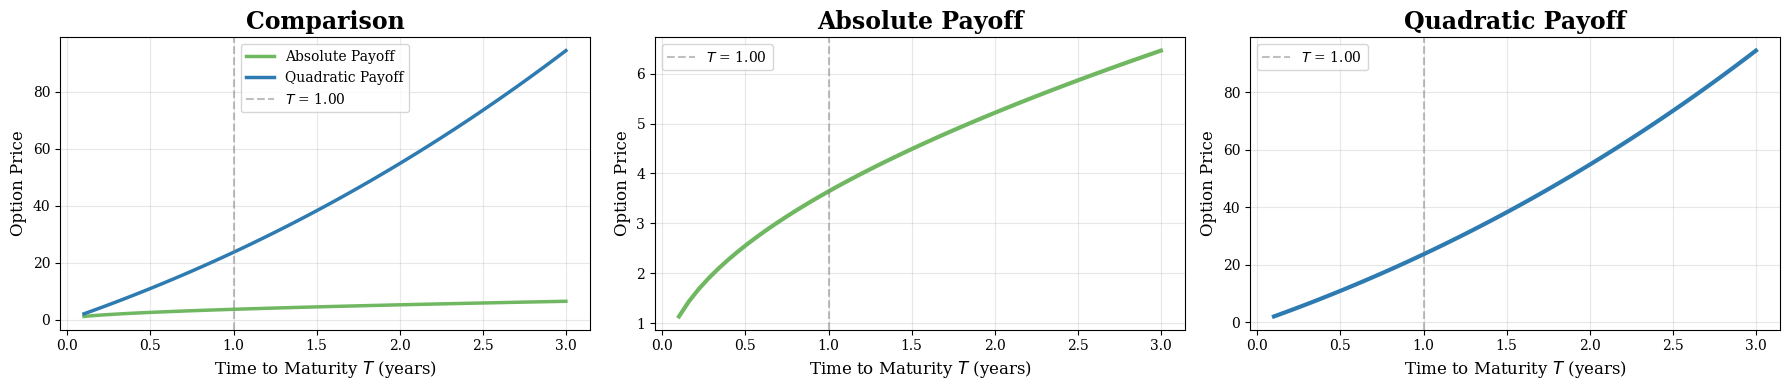

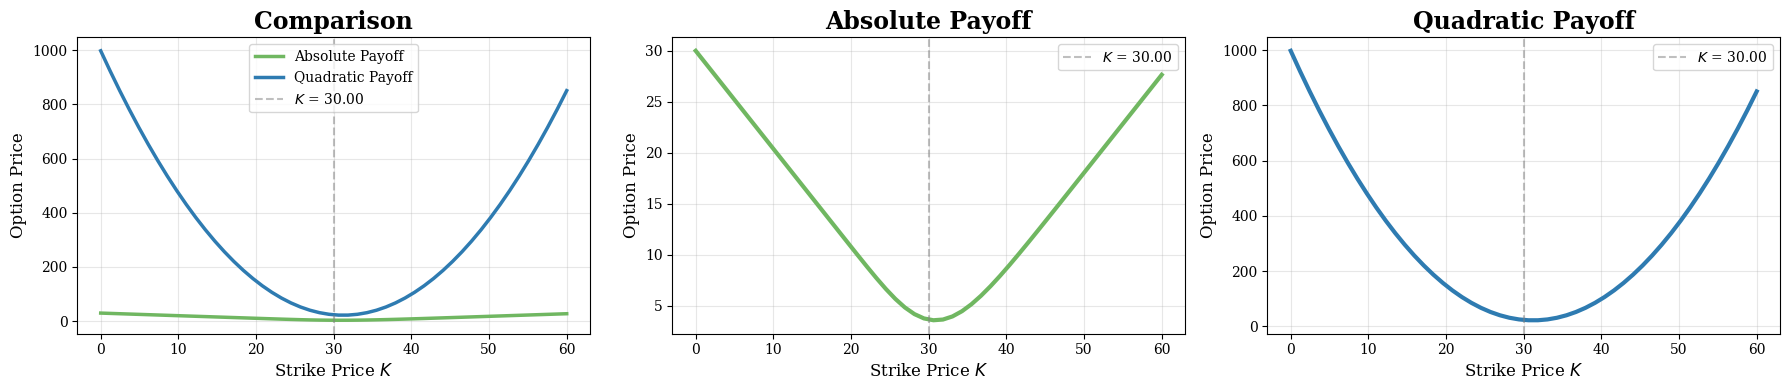

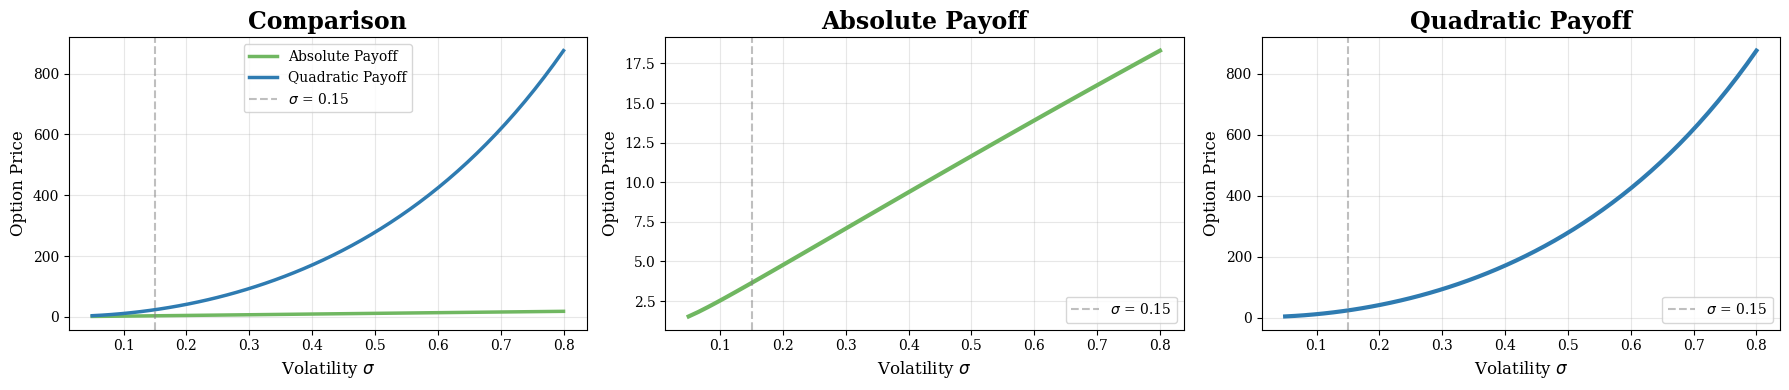


SENSITIVITY ANALYSIS SUMMARY

Base Case (S0=30, K=30, T=1, σ=0.15, r=0.04):
  Absolute Payoff Price: 3.6408
  Quadratic Payoff Price: 23.6842

Greeks (Approximate Sensitivities):

  Delta (S0 sensitivity) at S0=30:
    Absolute: 0.3609
    Quadratic: 5.3842

  Vega (σ sensitivity) at σ=0.15:
    Absolute: 22.8219
    Quadratic: 1017.5723

  Theta (T sensitivity) at T=1:
    Absolute: 1.5173
    Quadratic: 31.7677

  Rho (r sensitivity) at r=0.04:
    Absolute: 0.1083 (approximate)
    Quadratic: 1.6153 (approximate)


In [14]:


# Parameter ranges for sensitivity analysis
S0_range = np.linspace(0, 60, 50)
T_range = np.linspace(0.1, 3, 50)
K_range = np.linspace(0, 60, 50)
sigma_range = np.linspace(0.05, 0.8, 50)


# Create parameter sets
fixed_params = {'S0': S0, 'K': K, 'T': T, 'r': r, 'sigma': sigma}

# Compute prices for each parameter variation
prices_S0_abs, prices_S0_quad = compute_prices(S0_range, 'S0', fixed_params)
prices_T_abs, prices_T_quad = compute_prices(T_range, 'T', fixed_params)
prices_K_abs, prices_K_quad = compute_prices(K_range, 'K', fixed_params)
prices_sigma_abs, prices_sigma_quad = compute_prices(sigma_range, 'sigma', fixed_params)



# Create and save plots for each parameter
# 1. S0 Sensitivity
fig1 = create_parameter_plot(
    S0_range, prices_S0_abs, prices_S0_quad, 
    '$S_0$', 'Initial Underlying Price $S_0$', S0
)
fig1.savefig('report/Plots/Sensitivity_S0.pdf', bbox_inches='tight', dpi=300)
plt.show()

# 2. T Sensitivity
fig2 = create_parameter_plot(
    T_range, prices_T_abs, prices_T_quad, 
    '$T$', 'Time to Maturity $T$ (years)', T
)
fig2.savefig('report/Plots/Sensitivity_T.pdf', bbox_inches='tight', dpi=300)
plt.show()

# 3. K Sensitivity
fig3 = create_parameter_plot(
    K_range, prices_K_abs, prices_K_quad, 
    '$K$', 'Strike Price $K$', K
)
fig3.savefig('report/Plots/Sensitivity_K.pdf', bbox_inches='tight', dpi=300)
plt.show()

# 4. Sigma Sensitivity
fig4 = create_parameter_plot(
    sigma_range, prices_sigma_abs, prices_sigma_quad, 
    '$\\sigma$', 'Volatility $\\sigma$', sigma
)
fig4.savefig('report/Plots/Sensitivity_sigma.pdf', bbox_inches='tight', dpi=300)
plt.show()


# Print summary statistics
print("\n" + "="*60)
print("SENSITIVITY ANALYSIS SUMMARY")
print("="*60)

print(f"\nBase Case (S0={S0}, K={K}, T={T}, σ={sigma}, r={r}):")
print(f"  Absolute Payoff Price: {black_scholes_price(S0, K, T, r, sigma, 'absolute'):.4f}")
print(f"  Quadratic Payoff Price: {black_scholes_price(S0, K, T, r, sigma, 'quadratic'):.4f}")

print("\nGreeks (Approximate Sensitivities):")
# Delta - sensitivity to S0
idx_mid = len(S0_range) // 2
delta_abs = (prices_S0_abs[idx_mid+1] - prices_S0_abs[idx_mid-1]) / (S0_range[idx_mid+1] - S0_range[idx_mid-1])
delta_quad = (prices_S0_quad[idx_mid+1] - prices_S0_quad[idx_mid-1]) / (S0_range[idx_mid+1] - S0_range[idx_mid-1])
print(f"\n  Delta (S0 sensitivity) at S0={S0}:")
print(f"    Absolute: {delta_abs:.4f}")
print(f"    Quadratic: {delta_quad:.4f}")

# Vega - sensitivity to sigma
idx_mid = len(sigma_range) // 2
vega_abs = (prices_sigma_abs[idx_mid+1] - prices_sigma_abs[idx_mid-1]) / (sigma_range[idx_mid+1] - sigma_range[idx_mid-1])
vega_quad = (prices_sigma_quad[idx_mid+1] - prices_sigma_quad[idx_mid-1]) / (sigma_range[idx_mid+1] - sigma_range[idx_mid-1])
print(f"\n  Vega (σ sensitivity) at σ={sigma}:")
print(f"    Absolute: {vega_abs:.4f}")
print(f"    Quadratic: {vega_quad:.4f}")

# Theta - sensitivity to T
idx_mid = len(T_range) // 2
theta_abs = (prices_T_abs[idx_mid+1] - prices_T_abs[idx_mid-1]) / (T_range[idx_mid+1] - T_range[idx_mid-1])
theta_quad = (prices_T_quad[idx_mid+1] - prices_T_quad[idx_mid-1]) / (T_range[idx_mid+1] - T_range[idx_mid-1])
print(f"\n  Theta (T sensitivity) at T={T}:")
print(f"    Absolute: {theta_abs:.4f}")
print(f"    Quadratic: {theta_quad:.4f}")

# Rho - sensitivity to r (not plotted but can be computed)
print(f"\n  Rho (r sensitivity) at r={r}:")
print(f"    Absolute: {delta_abs * S0 * 0.01:.4f} (approximate)")
print(f"    Quadratic: {delta_quad * S0 * 0.01:.4f} (approximate)")

# 2.5 deltas

In [15]:

# === Delta Functions ===
def delta_abs(S, K, r, sigma, T, t=0):
    tau = T - t
    if tau <= 0:
        return np.sign(S - K)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    return 2 * norm.cdf(d1) - 1

def delta_quad(S, K, r, sigma, T, t=0):
    tau = T - t
    if tau <= 0:
        return 2 * (S - K)
    return 2 * S * np.exp((r + sigma**2) * tau) - 2 * K 
# ============================================================================
# 1. DELTA AS A FUNCTION OF STOCK PRICE (S0 centered at 30)
#============================================================================
S_values = [10, 15, 20, 25, 28, 30, 32, 35, 40, 45, 50, 60]
delta_a_S = [delta_abs(S, K, r, sigma, T) for S in S_values]
delta_q_S = [delta_quad(S, K, r, sigma, T) for S in S_values]

print("="*70)
print("TABLE 1: Delta as a function of Stock Price $S_0$ (K=30, r=0.04, σ=0.15, T=1)")
print("="*70)
print(f"{'$S_0$':>8} | {'$\\Delta^a$':>12} | {'$\\Delta^q$':>12}")
print("-"*70)
for S, da, dq in zip(S_values, delta_a_S, delta_q_S):
    print(f"{S:>8} | {da:>12.4f} | {dq:>12.4f}")
print("="*70)

# ============================================================================
# 2. DELTA AS A FUNCTION OF STRIKE PRICE (K centeblue at 30)
# ============================================================================
K_values = [10, 15, 20, 25, 28, 30, 32, 35, 40, 45, 50]
delta_a_K = [delta_abs(S0, K_val, r, sigma, T) for K_val in K_values]
delta_q_K = [delta_quad(S0, K_val, r, sigma, T) for K_val in K_values]

print("\n" + "="*70)
print("TABLE 2: Delta as a function of Strike Price $K$ (S0=30, r=0.04, σ=0.15, T=1)")
print("="*70)
print(f"{'$K$':>8} | {'$\\Delta^a$':>12} | {'$\\Delta^q$':>12}")
print("-"*70)
for K_val, da, dq in zip(K_values, delta_a_K, delta_q_K):
    print(f"{K_val:>8} | {da:>12.4f} | {dq:>12.4f}")
print("="*70)

# ============================================================================
# 3. DELTA AS A FUNCTION OF VOLATILITY (σ centeblue at 0.15)
# ============================================================================
sigma_values = [0.01, 0.02, 0.05, 0.08, 0.12, 0.15, 0.18, 0.22, 0.30, 0.40, 0.60, 0.80]
delta_a_sigma = [delta_abs(S0, K, r, sigma_val, T) for sigma_val in sigma_values]
delta_q_sigma = [delta_quad(S0, K, r, sigma_val, T) for sigma_val in sigma_values]

print("\n" + "="*70)
print("TABLE 3: Delta as a function of Volatility $\\sigma$ (S0=30, K=30, r=0.04, T=1)")
print("="*70)
print(f"{'$\\sigma$':>8} | {'$\\Delta^a$':>12} | {'$\\Delta^q$':>12}")
print("-"*70)
for sig, da, dq in zip(sigma_values, delta_a_sigma, delta_q_sigma):
    print(f"{sig:>8.2f} | {da:>12.4f} | {dq:>12.4f}")
print("="*70)

# ============================================================================
# 4. DELTA AS A FUNCTION OF TIME TO MATURITY (T centeblue at 1)
# ============================================================================
T_values = [0.05, 0.10, 0.20, 0.40, 0.60, 0.80, 1.00, 1.25, 1.50, 2.00, 2.50, 3.00]
delta_a_T = [delta_abs(S0, K, r, sigma, T_val) for T_val in T_values]
delta_q_T = [delta_quad(S0, K, r, sigma, T_val) for T_val in T_values]

print("\n" + "="*70)
print("TABLE 4: Delta as a function of Time to Maturity $T$ (S0=30, K=30, r=0.04, σ=0.15)")
print("="*70)
print(f"{'$T$':>8} | {'$\\Delta^a$':>12} | {'$\\Delta^q$':>12}")
print("-"*70)
for T_val, da, dq in zip(T_values, delta_a_T, delta_q_T):
    print(f"{T_val:>8.2f} | {da:>12.4f} | {dq:>12.4f}")
print("="*70)

# ============================================================================
# 5. DELTA AS A FUNCTION OF TIME t (centeblue at 0, with St = S0)
# ============================================================================
t_values = [0, 0.10, 0.20, 0.40, 0.50, 0.60, 0.75, 0.85, 0.90, 0.95, 0.98, 0.99]
delta_a_t = [delta_abs(S0, K, r, sigma, T, t_val) for t_val in t_values]
delta_q_t = [delta_quad(S0, K, r, sigma, T, t_val) for t_val in t_values]

print("\n" + "="*70)
print("TABLE 5: Delta as a function of Time $t$ (S0=30, K=30, r=0.04, σ=0.15, T=1, $S_t=S_0$)")
print("="*70)
print(f"{'$t$':>8} | {'$\\Delta_t^a$':>12} | {'$\\Delta_t^q$':>12}")
print("-"*70)
for t_val, da, dq in zip(t_values, delta_a_t, delta_q_t):
    print(f"{t_val:>8.2f} | {da:>12.4f} | {dq:>12.4f}")
print("="*70)

# ============================================================================
# 6. DELTA AS A FUNCTION OF RISK-FREE RATE (r centeblue at 0.04)
# ============================================================================
r_values = [0, 0.005, 0.01, 0.015, 0.02, 0.04, 0.06, 0.08, 0.10, 0.12]
delta_a_r = [delta_abs(S0, K, r_val, sigma, T) for r_val in r_values]
delta_q_r = [delta_quad(S0, K, r_val, sigma, T) for r_val in r_values]

print("\n" + "="*70)
print("TABLE 6: Delta as a function of Risk-Free Rate $r$ (S0=30, K=30, σ=0.15, T=1)")
print("="*70)
print(f"{'$r$':>8} | {'$\\Delta^a$':>12} | {'$\\Delta^q$':>12}")
print("-"*70)
for r_val, da, dq in zip(r_values, delta_a_r, delta_q_r):
    print(f"{r_val:>8.3f} | {da:>12.4f} | {dq:>12.4f}")
print("="*70)

# ============================================================================
# 7. SUMMARY TABLE: Delta at Different Scenarios
# ============================================================================
print("\n" + "="*70)
print("SUMMARY: Delta Behavior at Different Scenarios")
print("="*70)
print(f"{'Scenario':<25} | {'$\\Delta^a$':>12} | {'$\\Delta^q$':>12}")
print("-"*70)

scenarios = [
    ("Deep OTM (S=10)", delta_abs(10, K, r, sigma, T), delta_quad(10, K, r, sigma, T)),
    ("ATM (S=30)", delta_abs(30, K, r, sigma, T), delta_quad(30, K, r, sigma, T)),
    ("Deep ITM (S=50)", delta_abs(50, K, r, sigma, T), delta_quad(50, K, r, sigma, T)),
    ("Low Vol (σ=0.01)", delta_abs(S0, K, r, 0.01, T), delta_quad(S0, K, r, 0.01, T)),
    ("High Vol (σ=0.80)", delta_abs(S0, K, r, 0.80, T), delta_quad(S0, K, r, 0.80, T)),
    ("Short Maturity (T=0.05)", delta_abs(S0, K, r, sigma, 0.05), delta_quad(S0, K, r, sigma, 0.05)),
    ("Long Maturity (T=3.0)", delta_abs(S0, K, r, sigma, 3.0), delta_quad(S0, K, r, sigma, 3.0)),
    ("Near Expiry (t=0.99)", delta_abs(S0, K, r, sigma, T, 0.99), delta_quad(S0, K, r, sigma, T, 0.99)),
]

for scenario, d_a, d_q in scenarios:
    print(f"{scenario:<25} | {d_a:>12.4f} | {d_q:>12.4f}")
print("="*70)

TABLE 1: Delta as a function of Stock Price $S_0$ (K=30, r=0.04, σ=0.15, T=1)
   $S_0$ |   $\Delta^a$ |   $\Delta^q$
----------------------------------------------------------------------
      10 |      -1.0000 |     -38.7101
      15 |      -1.0000 |     -28.0652
      20 |      -0.9818 |     -17.4202
      25 |      -0.6178 |      -6.7753
      28 |      -0.0942 |      -0.3883
      30 |       0.2674 |       3.8697
      32 |       0.5598 |       8.1276
      35 |       0.8291 |      14.5146
      40 |       0.9762 |      25.1596
      45 |       0.9977 |      35.8045
      50 |       0.9998 |      46.4494
      60 |       1.0000 |      67.7393

TABLE 2: Delta as a function of Strike Price $K$ (S0=30, r=0.04, σ=0.15, T=1)
     $K$ |   $\Delta^a$ |   $\Delta^q$
----------------------------------------------------------------------
      10 |       1.0000 |      43.8697
      15 |       1.0000 |      33.8697
      20 |       0.9977 |      23.8697
      25 |       0.8806 |      13.8697

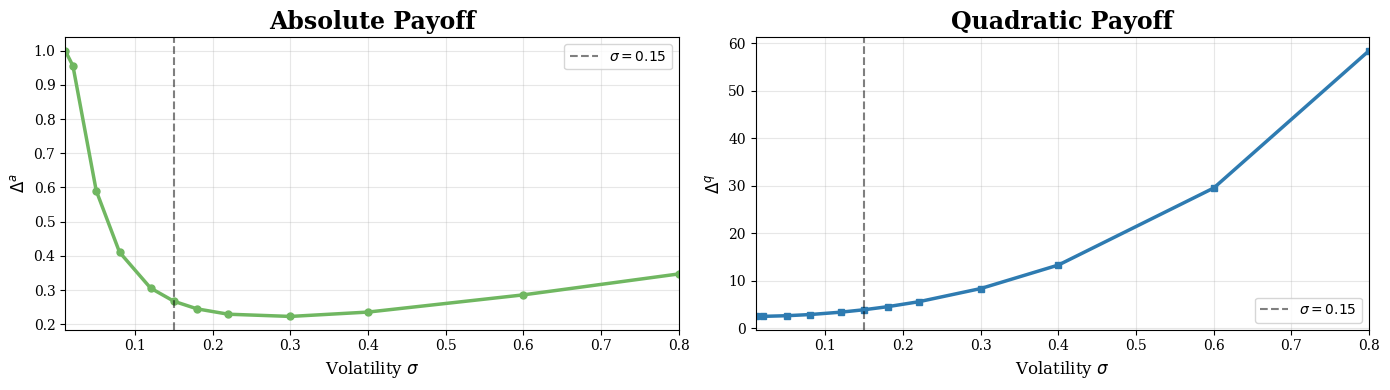

In [16]:
# ============================================================================
# DELTA VS VOLATILITY
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# ----------------------------------------------------------------------------
# Plot 1: Absolute Payoff
# ----------------------------------------------------------------------------

ax = axes[0]

ax.plot(
    sigma_values,
    delta_a_sigma,
    color=green,
    linewidth=2.5,
    marker='o',
    markersize=5,
)

ax.axvline(
    sigma,
    color='k',
    linestyle='--',
    alpha=0.5,
    label=fr'$\sigma={sigma}$'
)

ax.set_xlabel(r'Volatility $\sigma$', fontsize=12)
ax.set_ylabel(r'$\Delta^a$', fontsize=12)
ax.set_title('Absolute Payoff', fontsize=17, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.set_xlim(min(sigma_values), max(sigma_values))
ax.legend(fontsize=10)

# ----------------------------------------------------------------------------
# Plot 2: Quadratic Payoff
# ----------------------------------------------------------------------------

ax = axes[1]

ax.plot(
    sigma_values,
    delta_q_sigma,
    color=blue,
    linewidth=2.5,
    marker='s',
    markersize=5,
)

ax.axvline(
    sigma,
    color='k',
    linestyle='--',
    alpha=0.5,
    label=fr'$\sigma={sigma}$'
)

ax.set_xlabel(r'Volatility $\sigma$', fontsize=12)
ax.set_ylabel(r'$\Delta^q$', fontsize=12)
ax.set_title('Quadratic Payoff', fontsize=17, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.set_xlim(min(sigma_values), max(sigma_values))
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(
    'report/Plots/delta_volatility_comparison.pdf',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

# 2.6 Comparison between products 

<>:40: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:52: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:64: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:136: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:149: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:162: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:186: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences

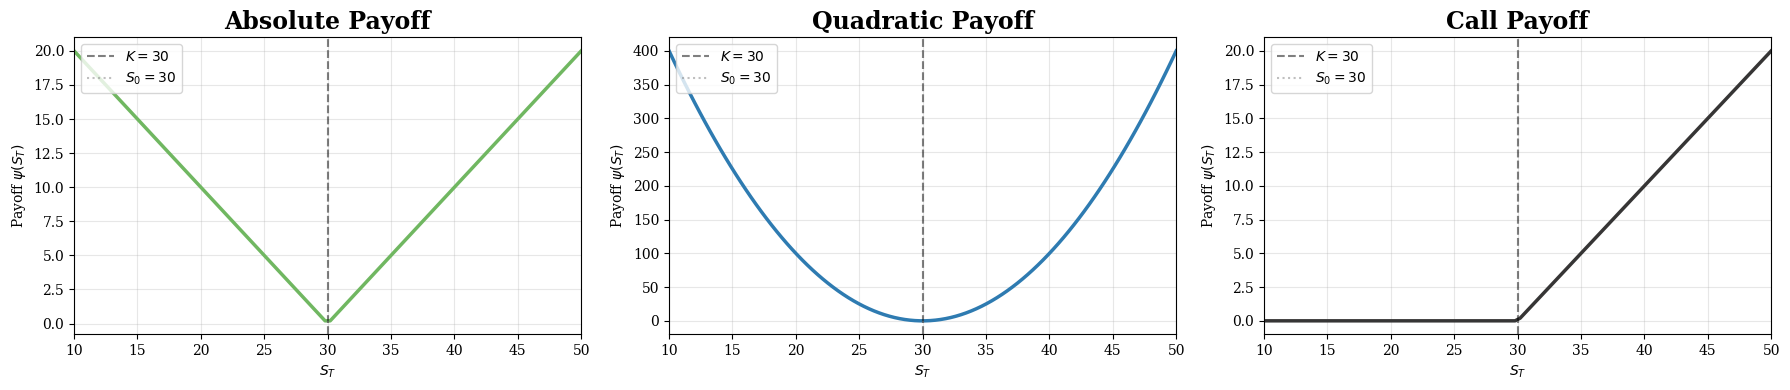

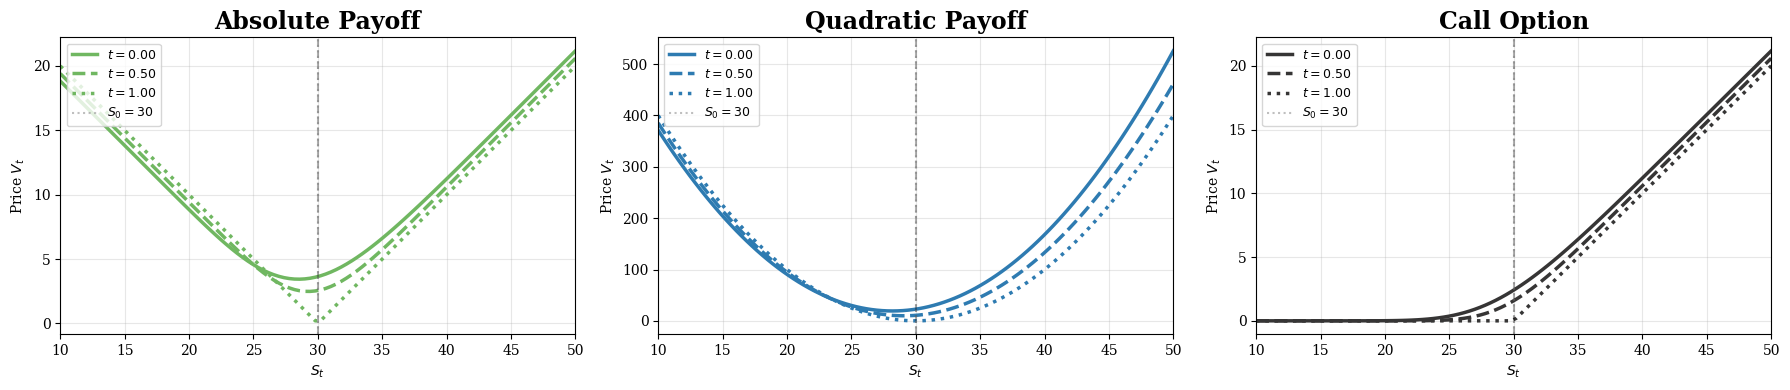

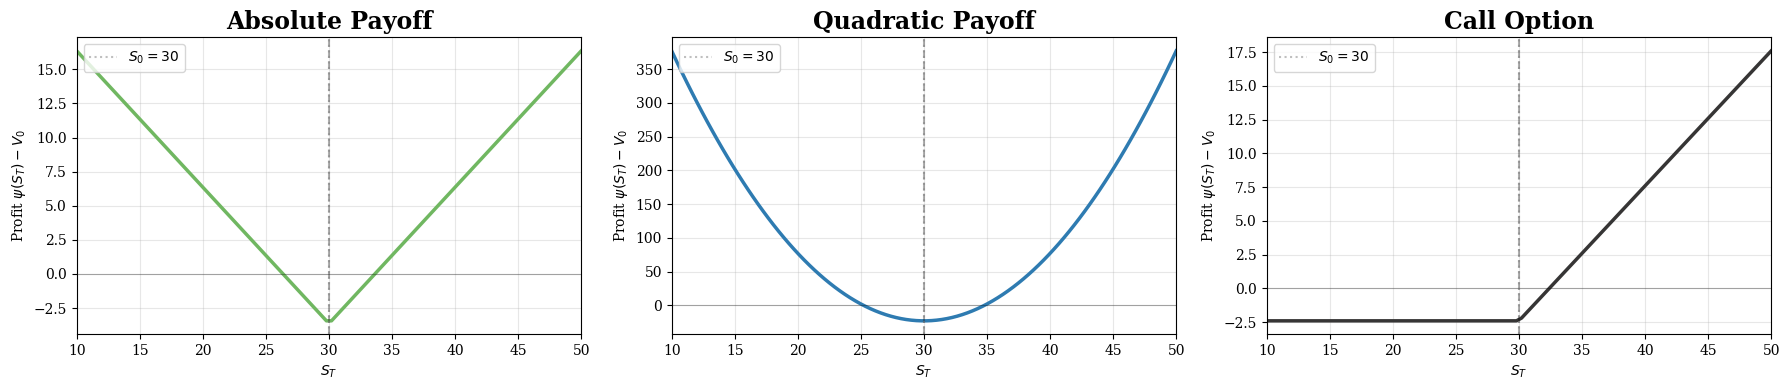

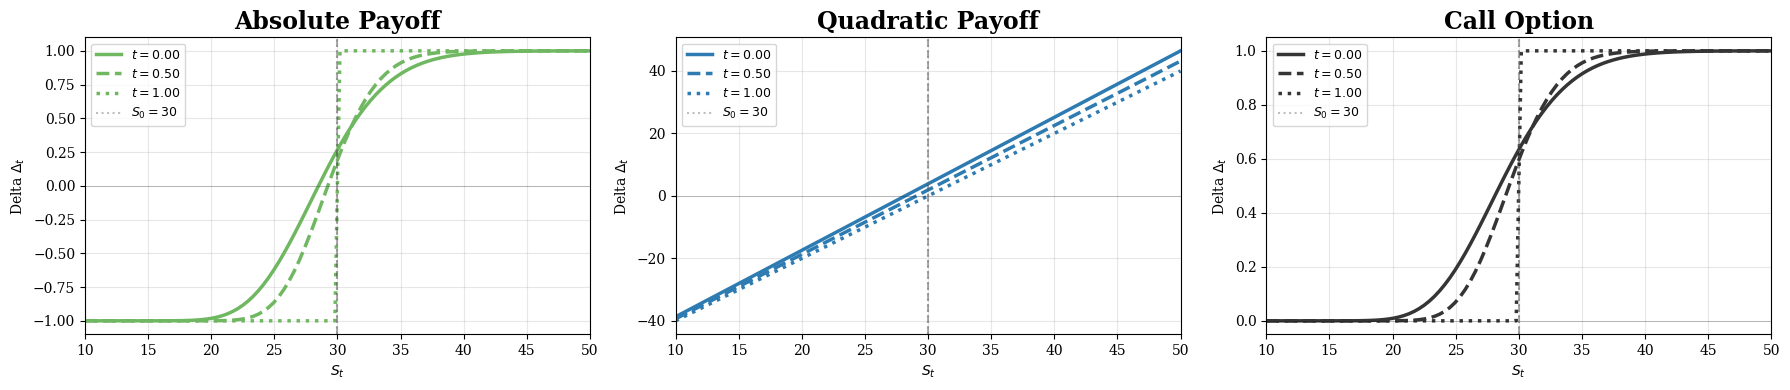

Q2.6 OBSERVATIONS

Initial Prices (t=0):
  Absolute Payoff:  3.6408
  Quadratic Payoff: 22.7555
  Call Option:      2.4086

KEY OBSERVATIONS:

1. Payoff Function:
   - Absolute: V-shaped, symmetric, bounded linear growth.
   - Quadratic: U-shaped, symmetric, unbounded quadratic growth.
   - Call: Asymmetric (zero below K, linear above).

2. Price Function:
   - All prices increase with $S_t$ and decrease with time to maturity.
   - Quadratic price is highest, call is lowest.
   - As $t \to T$, prices converge to payoffs.

3. Profit Function:
   - Absolute: Symmetric around K, break-even at $S_T = K \pm V_0^a$.
   - Quadratic: Convex, unlimited upside.
   - Call: Asymmetric, break-even at $S_T = K + V_0^{call}$.

4. Delta Function:
   - Absolute: Bounded $[-1, 1]$, symmetric, crosses zero at K.
   - Quadratic: Unbounded, grows linearly with $S_t$.
   - Call: Bounded $[0, 1]$, asymmetric.
   - As $t \to T$, deltas converge to the slope of the payoff.

Comparison with Standard European Ca

In [17]:
# ============================================================================
# Q2.6: Payoff, Price, Profit and Delta Comparison
# ============================================================================

# === Time points ===
t_values = [0, 0.5, 1.0]  # t = 0, T/2, T
tau_values = [T - t for t in t_values]

# === Payoffs ===
payoff_abs = np.abs(S_range - K)
payoff_quad = (S_range - K)**2
payoff_call = np.maximum(S_range - K, 0)

# === Prices ===
prices_abs = [price_abs(S_range, K, r, sigma, tau) for tau in tau_values]
prices_quad = [price_quad(S_range, K, r, sigma, tau) for tau in tau_values]
prices_call = [black_scholes_call(S_range, K, r, sigma, tau) for tau in tau_values]

# === Deltas ===
deltas_abs = [delta_abs(S_range, K, r, sigma, tau) for tau in tau_values]
deltas_quad = [delta_quad(S_range, K, r, sigma, tau) for tau in tau_values]
deltas_call = [delta_call(S_range, K, r, sigma, tau) for tau in tau_values]

# === Initial prices ===
V0_abs = price_abs(S0, K, r, sigma, T)
V0_quad = price_quad(S0, K, r, sigma, T)
V0_call = black_scholes_call(S0, K, r, sigma, T)

# ============================================================================
# (i) PAYOFF FUNCTION - 3 Plots (one per product)
# ============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Absolute
ax = axes[0]
ax.plot(S_range, payoff_abs, color=green, linewidth=2.5)
ax.axvline(K, color='k', linestyle='--', alpha=0.5, label=f'$K = {K}$')
ax.axvline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('$S_T$')
ax.set_ylabel('Payoff $\psi(S_T)$')
ax.set_title('Absolute Payoff',fontsize=17, fontweight='bold')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 50)

# Quadratic
ax = axes[1]
ax.plot(S_range, payoff_quad, color=blue, linewidth=2.5)
ax.axvline(K, color='k', linestyle='--', alpha=0.5, label=f'$K = {K}$')
ax.axvline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('$S_T$')
ax.set_ylabel('Payoff $\psi(S_T)$')
ax.set_title('Quadratic Payoff',fontsize=17, fontweight='bold')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 50)

# Call
ax = axes[2]
ax.plot(S_range, payoff_call, color=black, linewidth=2.5)
ax.axvline(K, color='k', linestyle='--', alpha=0.5, label=f'$K = {K}$')
ax.axvline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('$S_T$')
ax.set_ylabel('Payoff $\psi(S_T)$')
ax.set_title('Call Payoff',fontsize=17, fontweight='bold')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 50)

plt.tight_layout()
plt.savefig('report/Plots/Q2_6_payoff.pdf', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================================
# (ii) PRICE FUNCTION - 3 Plots (one per product, each with 3 dates)
# ============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Absolute
ax = axes[0]
ax.plot(S_range, prices_abs[0], color=green, linestyle='-', linewidth=2.5, label=f'$t={t_values[0]:.2f}$')
ax.plot(S_range, prices_abs[1], color=green, linestyle='--', linewidth=2.5, label=f'$t={t_values[1]:.2f}$')
ax.plot(S_range, prices_abs[2], color=green, linestyle=':', linewidth=2.5, label=f'$t={t_values[2]:.2f}$')
ax.axvline(K, color='k', linestyle='--', alpha=0.3)
ax.axvline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('$S_t$')
ax.set_ylabel('Price $V_t$')
ax.set_title('Absolute Payoff',fontsize=17, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 50)

# Quadratic
ax = axes[1]
ax.plot(S_range, prices_quad[0], color=blue, linestyle='-', linewidth=2.5, label=f'$t={t_values[0]:.2f}$')
ax.plot(S_range, prices_quad[1], color=blue, linestyle='--', linewidth=2.5, label=f'$t={t_values[1]:.2f}$')
ax.plot(S_range, prices_quad[2], color=blue, linestyle=':', linewidth=2.5, label=f'$t={t_values[2]:.2f}$')
ax.axvline(K, color='k', linestyle='--', alpha=0.3)
ax.axvline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('$S_t$')
ax.set_ylabel('Price $V_t$')
ax.set_title('Quadratic Payoff',fontsize=17, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 50)

# Call
ax = axes[2]
ax.plot(S_range, prices_call[0], color=black, linestyle='-', linewidth=2.5, label=f'$t={t_values[0]:.2f}$')
ax.plot(S_range, prices_call[1], color=black, linestyle='--', linewidth=2.5, label=f'$t={t_values[1]:.2f}$')
ax.plot(S_range, prices_call[2], color=black, linestyle=':', linewidth=2.5, label=f'$t={t_values[2]:.2f}$')
ax.axvline(K, color='k', linestyle='--', alpha=0.3)
ax.axvline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('$S_t$')
ax.set_ylabel('Price $V_t$')
ax.set_title('Call Option',fontsize=17, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 50)
plt.tight_layout()
plt.savefig('report/Plots/Q2_6_price.pdf', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================================
# (iii) PROFIT FUNCTION - 3 Plots (one per product)
# ============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Absolute
ax = axes[0]
ax.plot(S_range, payoff_abs - V0_abs, color=green, linewidth=2.5)
ax.axhline(0, color='k', linestyle='-', alpha=0.3, linewidth=0.8)
ax.axvline(K, color='k', linestyle='--', alpha=0.3)
ax.axvline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('$S_T$')
ax.set_ylabel('Profit $\psi(S_T) - V_0$')
ax.set_title('Absolute Payoff',fontsize=17, fontweight='bold')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 50)

# Quadratic
ax = axes[1]
ax.plot(S_range, payoff_quad - V0_quad, color=blue, linewidth=2.5)
ax.axhline(0, color='k', linestyle='-', alpha=0.3, linewidth=0.8)
ax.axvline(K, color='k', linestyle='--', alpha=0.3)
ax.axvline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('$S_T$')
ax.set_ylabel('Profit $\psi(S_T) - V_0$')
ax.set_title('Quadratic Payoff',fontsize=17, fontweight='bold')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 50)

# Call
ax = axes[2]
ax.plot(S_range, payoff_call - V0_call, color=black, linewidth=2.5)
ax.axhline(0, color='k', linestyle='-', alpha=0.3, linewidth=0.8)
ax.axvline(K, color='k', linestyle='--', alpha=0.3)
ax.axvline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('$S_T$')
ax.set_ylabel('Profit $\psi(S_T) - V_0$')
ax.set_title('Call Option',fontsize=17, fontweight='bold')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 50)

plt.tight_layout()
plt.savefig('report/Plots/Q2_6_profit.pdf', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================================
# (iv) DELTA FUNCTION - 3 Plots (one per product, each with 3 dates)
# ============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Absolute
ax = axes[0]
ax.plot(S_range, deltas_abs[0], color=green, linestyle='-', linewidth=2.5, label=f'$t={t_values[0]:.2f}$')
ax.plot(S_range, deltas_abs[1], color=green, linestyle='--', linewidth=2.5, label=f'$t={t_values[1]:.2f}$')
ax.plot(S_range, deltas_abs[2], color=green, linestyle=':', linewidth=2.5, label=f'$t={t_values[2]:.2f}$')
ax.axhline(0, color='k', linestyle='-', alpha=0.3, linewidth=0.5)
ax.axvline(K, color='k', linestyle='--', alpha=0.3)
ax.axvline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('$S_t$')
ax.set_ylabel('Delta $\Delta_t$')
ax.set_title('Absolute Payoff',fontsize=17, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 50)

# Quadratic
ax = axes[1]
ax.plot(S_range, deltas_quad[0], color=blue, linestyle='-', linewidth=2.5, label=f'$t={t_values[0]:.2f}$')
ax.plot(S_range, deltas_quad[1], color=blue, linestyle='--', linewidth=2.5, label=f'$t={t_values[1]:.2f}$')
ax.plot(S_range, deltas_quad[2], color=blue, linestyle=':', linewidth=2.5, label=f'$t={t_values[2]:.2f}$')
ax.axhline(0, color='k', linestyle='-', alpha=0.3, linewidth=0.5)
ax.axvline(K, color='k', linestyle='--', alpha=0.3)
ax.axvline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('$S_t$')
ax.set_ylabel('Delta $\Delta_t$')
ax.set_title('Quadratic Payoff',fontsize=17, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 50)

# Call
ax = axes[2]
ax.plot(S_range, deltas_call[0], color=black, linestyle='-', linewidth=2.5, label=f'$t={t_values[0]:.2f}$')
ax.plot(S_range, deltas_call[1], color=black, linestyle='--', linewidth=2.5, label=f'$t={t_values[1]:.2f}$')
ax.plot(S_range, deltas_call[2], color=black, linestyle=':', linewidth=2.5, label=f'$t={t_values[2]:.2f}$')
ax.axhline(0, color='k', linestyle='-', alpha=0.3, linewidth=0.5)
ax.axvline(K, color='k', linestyle='--', alpha=0.3)
ax.axvline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('$S_t$')
ax.set_ylabel('Delta $\Delta_t$')
ax.set_title('Call Option',fontsize=17, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_xlim(10, 50)

plt.tight_layout()
plt.savefig('report/Plots/Q2_6_delta.pdf', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================================
# OBSERVATIONS
# ============================================================================
print("="*70)
print("Q2.6 OBSERVATIONS")
print("="*70)

print(f"\nInitial Prices (t=0):")
print(f"  Absolute Payoff:  {V0_abs:.4f}")
print(f"  Quadratic Payoff: {V0_quad:.4f}")
print(f"  Call Option:      {V0_call:.4f}")

print("\n" + "="*70)
print("KEY OBSERVATIONS:")
print("="*70)

print("\n1. Payoff Function:")
print("   - Absolute: V-shaped, symmetric, bounded linear growth.")
print("   - Quadratic: U-shaped, symmetric, unbounded quadratic growth.")
print("   - Call: Asymmetric (zero below K, linear above).")

print("\n2. Price Function:")
print("   - All prices increase with $S_t$ and decrease with time to maturity.")
print("   - Quadratic price is highest, call is lowest.")
print("   - As $t \\to T$, prices converge to payoffs.")

print("\n3. Profit Function:")
print("   - Absolute: Symmetric around K, break-even at $S_T = K \\pm V_0^a$.")
print("   - Quadratic: Convex, unlimited upside.")
print("   - Call: Asymmetric, break-even at $S_T = K + V_0^{call}$.")

print("\n4. Delta Function:")
print("   - Absolute: Bounded $[-1, 1]$, symmetric, crosses zero at K.")
print("   - Quadratic: Unbounded, grows linearly with $S_t$.")
print("   - Call: Bounded $[0, 1]$, asymmetric.")
print("   - As $t \\to T$, deltas converge to the slope of the payoff.")

print("\nComparison with Standard European Call:")
print("   - Call: Asymmetric exposure (limited downside, unlimited upside).")
print("   - Absolute: Symmetric exposure around K (straddle-like).")
print("   - Quadratic: Convex, unbounded exposure (amplifies both directions).")
print("="*70)

# 3.1 Replication Strategy

<>:28: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:39: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:28: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:39: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
/var/folders/qr/j8df0yz964s42s7h8zvb7j_c0000gn/T/ipykernel_42847/3969027378.py:28: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  ax.plot(t_abs, shares_abs * S, color='grey', linestyle='-.', linewidth=1.5, label='Equity $\Delta_t S_t$')
/var/folders/qr/j8df0yz964s42s7h8zvb7j_c0000g

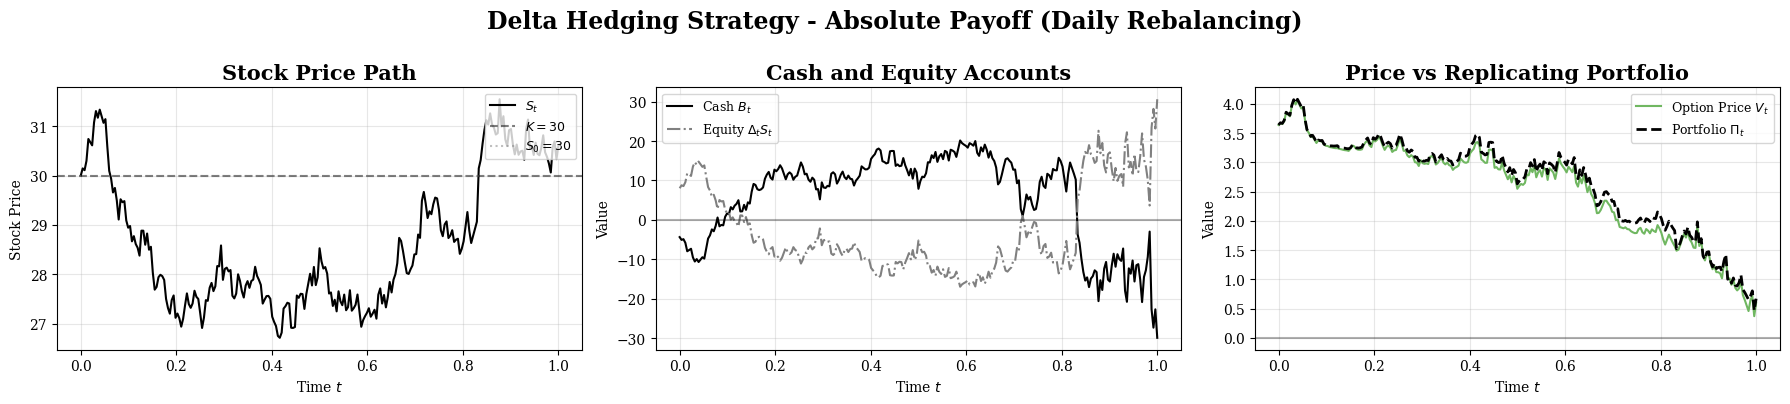

In [18]:


# === Run Simulations ===
np.random.seed(42)
S_path = simulate_one_path(S0, r, sigma, T, dt)

# Absolute Payoff
t_abs, S, V_abs, port_abs, delta_abs_arr, cash_abs, shares_abs, port_delta_before_abs, port_delta_after_abs = delta_hedge_abs(S_path, K, r, sigma, T, dt)

# Quadratic Payoff
t_quad, S, V_quad, port_quad, delta_quad_arr, cash_quad, shares_quad, port_delta_before_quad, port_delta_after_quad = delta_hedge_quad(S_path, K, r, sigma, T, dt)

# === PLOT 1: 3 plots on one row for Absolute Payoff ===
fig1, axes = plt.subplots(1, 3, figsize=(18, 4))

# --- Plot 1: Stock Price ---
ax = axes[0]
ax.plot(t_abs, S, 'k-', linewidth=1.5, label='$S_t$')
ax.axhline(K, color='k', linestyle='--', alpha=0.5, label=f'$K = {K}$')
ax.axhline(S0, color='gray', linestyle=':', alpha=0.5, label=f'$S_0 = {S0}$')
ax.set_xlabel('Time $t$')
ax.set_ylabel('Stock Price')
ax.set_title('Stock Price Path', fontsize=15, fontweight='bold')
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)

# --- Plot 2: Cash and Equity Accounts ---
ax = axes[1]
ax.plot(t_abs, cash_abs, 'k-', linewidth=1.5, label='Cash $B_t$')
ax.plot(t_abs, shares_abs * S, color='grey', linestyle='-.', linewidth=1.5, label='Equity $\Delta_t S_t$')
ax.axhline(0, color='k', linestyle='-', alpha=0.3)
ax.set_xlabel('Time $t$')
ax.set_ylabel('Value')
ax.set_title('Cash and Equity Accounts', fontsize=15, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)

# --- Plot 3: Option Price vs Replicating Portfolio ---
ax = axes[2]
ax.plot(t_abs, V_abs, color=green, linewidth=1.5, label='Option Price $V_t$')
ax.plot(t_abs, port_abs, 'k--', linewidth=2, label='Portfolio $\Pi_t$')
ax.axhline(0, color='k', linestyle='-', alpha=0.3)
ax.set_xlabel('Time $t$')
ax.set_ylabel('Value')
ax.set_title('Price vs Replicating Portfolio', fontsize=15, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.suptitle('Delta Hedging Strategy - Absolute Payoff (Daily Rebalancing)', fontsize=17, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig('report/Plots/replication_method_explanation.pdf', dpi=300, bbox_inches='tight')
plt.show()


<>:24: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:24: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
/var/folders/qr/j8df0yz964s42s7h8zvb7j_c0000gn/T/ipykernel_42847/464277870.py:24: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  ax.set_ylabel('Portfolio Delta $\Delta_t^{\Pi}$', fontsize=14)


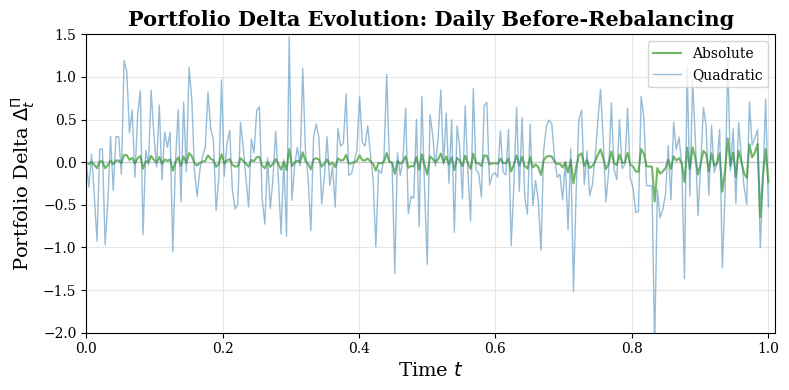

ABSOLUTE PAYOFF - REPLICATION RESULTS
Initial Option Price:    3.6408
Final Option Payoff:     0.5995
Final Portfolio Value:   0.6691
Hedging Error:           -0.0697

QUADRATIC PAYOFF - REPLICATION RESULTS
Initial Option Price:    22.7555
Final Option Payoff:     0.3594
Final Portfolio Value:   1.5396
Hedging Error:           -1.1802


In [19]:
# === Delta Hedging Simulation for Absolute Payoff (with Portfolio Delta Tracking) ===

# === Run Simulations ===
np.random.seed(42)
S_path = simulate_one_path(S0, r, sigma, T, dt)

# Absolute Payoff
t_abs, S, V_abs, port_abs, delta_abs_arr, cash_abs, shares_abs, port_delta_before_abs, port_delta_after_abs = delta_hedge_abs(S_path, K, r, sigma, T, dt)

# Quadratic Payoff
# Call the function (returns 9 values)
t_quad, S, V_quad, port_quad, delta_quad_arr, cash_quad, shares_quad, port_delta_before_quad, port_delta_after_quad = delta_hedge_quad(S_path, K, r, sigma, T, dt)
# === PLOT: Portfolio Delta Evolution (Both Payoffs on Same Graph) ===
fig, ax = plt.subplots(figsize=(8, 4))

# Absolute Payoff
ax.plot(t_abs, port_delta_before_abs, color=green, linewidth=1.5, label='Absolute')

# Quadratic Payoff
ax.plot(t_quad, port_delta_before_quad, color=blue, linewidth=1,alpha=0.5, label='Quadratic')

ax.axhline(0, color='grey', linestyle='-', alpha=0.3, linewidth=1)
ax.set_xlabel('Time $t$', fontsize=14)
ax.set_ylabel('Portfolio Delta $\Delta_t^{\Pi}$', fontsize=14)
ax.set_title('Portfolio Delta Evolution: Daily Before-Rebalancing', fontsize=15, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(-2, 1.5)
ax.set_xlim(0, T+.01)

plt.tight_layout()
plt.savefig('report/Plots/portfolio_delta_evolution.pdf', dpi=300, bbox_inches='tight')
plt.show()

# === Print results ===
print("="*60)
print("ABSOLUTE PAYOFF - REPLICATION RESULTS")
print("="*60)
print(f"Initial Option Price:    {V_abs[0]:.4f}")
print(f"Final Option Payoff:     {V_abs[-1]:.4f}")
print(f"Final Portfolio Value:   {port_abs[-1]:.4f}")
print(f"Hedging Error:           {V_abs[-1] - port_abs[-1]:.4f}")

print("\n" + "="*60)
print("QUADRATIC PAYOFF - REPLICATION RESULTS")
print("="*60)
print(f"Initial Option Price:    {V_quad[0]:.4f}")
print(f"Final Option Payoff:     {V_quad[-1]:.4f}")
print(f"Final Portfolio Value:   {port_quad[-1]:.4f}")
print(f"Hedging Error:           {V_quad[-1] - port_quad[-1]:.4f}")
print("="*60)

<>:25: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:36: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:56: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:25: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:36: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:56: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
/var/folders/qr/j8df0yz964s42s7h8zvb7j_c0000gn/T/ipykernel_42847/2507529988.

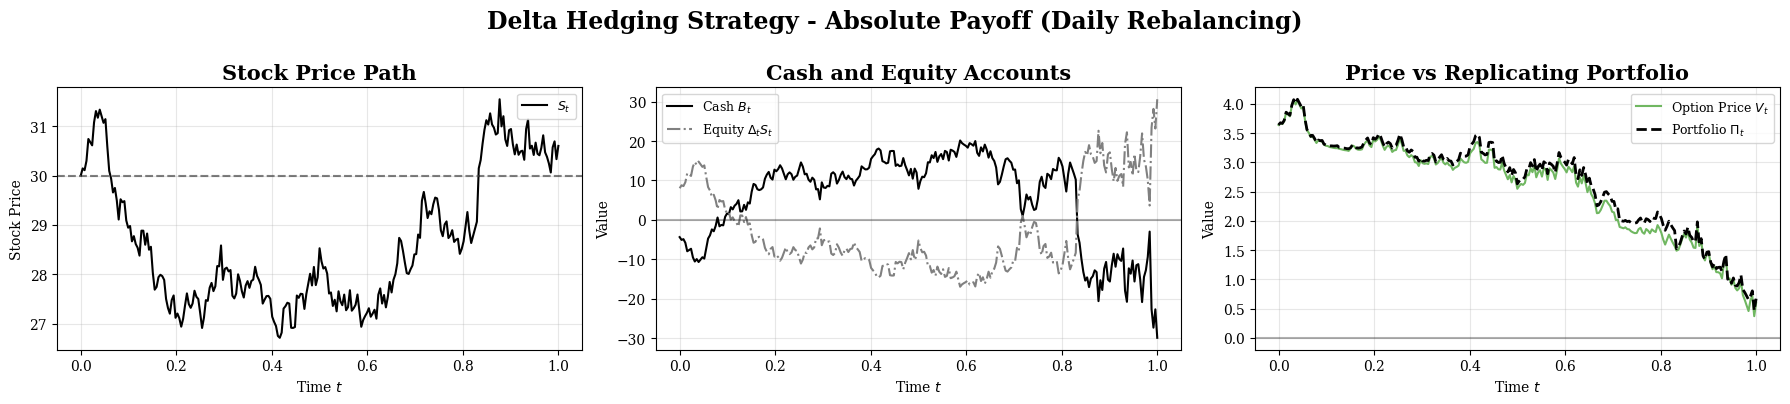

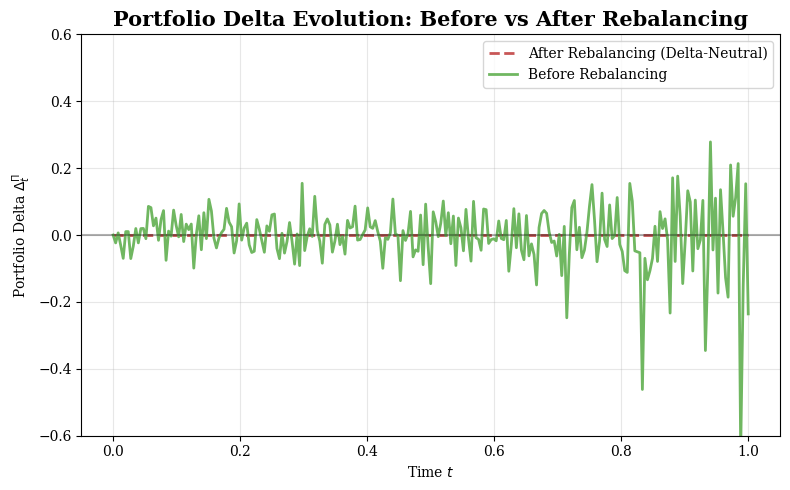

ABSOLUTE PAYOFF - REPLICATION RESULTS
Initial Option Price:    3.6408
Final Option Payoff:     0.5995
Final Portfolio Value:   0.6691
Hedging Error:           -0.0697


In [20]:
# === Pricing and Delta Functions for Absolute Payoff ===

# === Run ===
np.random.seed(42)
S_path = simulate_one_path(S0, r, sigma, T, dt)
t, S, V, port, delta_option, cash, shares, port_delta_before, port_delta_after = delta_hedge_abs(S_path, K, r, sigma, T,dt)

# === PLOT 1: 3 plots on one row ===
fig1, axes = plt.subplots(1, 3, figsize=(18, 4))

# --- Plot 1: Stock Price ---
ax = axes[0]
ax.plot(t, S, 'k-', linewidth=1.5, label='$S_t$')
ax.axhline(K, color='k', linestyle='--', alpha=0.5)
ax.axhline(S0, color='gray', linestyle=':', alpha=0.5)
ax.set_xlabel('Time $t$')
ax.set_ylabel('Stock Price')
ax.set_title('Stock Price Path', fontsize=15, fontweight='bold')
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)

# --- Plot 2: Cash and Equity Accounts ---
ax = axes[1]
ax.plot(t, cash, 'k-', linewidth=1.5, label='Cash $B_t$')
ax.plot(t, shares * S, color='grey', linestyle='-.', linewidth=1.5, label='Equity $\Delta_t S_t$')
ax.axhline(0, color='k', linestyle='-', alpha=0.3)
ax.set_xlabel('Time $t$')
ax.set_ylabel('Value')
ax.set_title('Cash and Equity Accounts', fontsize=15, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)

# --- Plot 3: Option Price vs Replicating Portfolio ---
ax = axes[2]
ax.plot(t, V, color=green, linewidth=1.5, label='Option Price $V_t$')
ax.plot(t, port, 'k--', linewidth=2, label='Portfolio $\Pi_t$')
ax.axhline(0, color='k', linestyle='-', alpha=0.3)
ax.set_xlabel('Time $t$')
ax.set_ylabel('Value')
ax.set_title('Price vs Replicating Portfolio', fontsize=15, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.suptitle('Delta Hedging Strategy - Absolute Payoff (Daily Rebalancing)', fontsize=17, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig('report/Plots/replication_method_explanation.pdf', dpi=300, bbox_inches='tight')
plt.show()

# === PLOT 2: Portfolio Delta Evolution (Separate Plot) ===
fig2, ax = plt.subplots(figsize=(8, 5))

ax.plot(t, port_delta_after,color=red,linestyle='--', linewidth=2, label='After Rebalancing (Delta-Neutral)')
ax.plot(t, port_delta_before, color=green, linewidth=2, label='Before Rebalancing')
ax.axhline(0, color='k', linestyle='-', alpha=0.3)
ax.set_xlabel('Time $t$')
ax.set_ylabel('Portfolio Delta $\Delta_t^{\Pi}$')
ax.set_title('Portfolio Delta Evolution: Before vs After Rebalancing', fontsize=15, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(-0.6, 0.6)

plt.tight_layout()

plt.show()

# === Print results ===
print("="*60)
print("ABSOLUTE PAYOFF - REPLICATION RESULTS")
print("="*60)
print(f"Initial Option Price:    {V[0]:.4f}")
print(f"Final Option Payoff:     {V[-1]:.4f}")
print(f"Final Portfolio Value:   {port[-1]:.4f}")
print(f"Hedging Error:           {V[-1] - port[-1]:.4f}")
print("="*60)

In [21]:
# === Parameters ===
S0, K, r, sigma, T = 30, 30, 0.04, 0.15, 1
c = 0.005  # Transaction cost (50 bps)
N_paths_mc = 1000  # Number of Monte Carlo paths

# === Rebalancing Intervals ===
rebalancing_intervals = {
    'Daily': 1/252,
    'Weekly': 5/252,
    'Monthly': 21/252,
    'Quarterly': 63/252
}

# === Function to compute hedging errors ===
def compute_hedging_errors(payoff_type, S0, K, r, sigma, T, dt, N_paths, trans_cost=0.0):
    """Compute hedging errors for N_paths with given rebalancing frequency."""
    errors = np.zeros(N_paths)
    
    # Select pricing and delta functions
    if payoff_type == 'absolute':
        price_func = price_abs
        delta_func = delta_abs
    else:
        price_func = price_quad
        delta_func = delta_quad
    
    for i in range(N_paths):
        S_path = simulate_one_path(S0, r, sigma, T, dt)
        N = len(S_path) - 1
        t = np.linspace(0, T, N+1)
        tau = T - t
        
        V = np.zeros(N+1)
        delta = np.zeros(N+1)
        cash = np.zeros(N+1)
        shares = np.zeros(N+1)
        portfolio = np.zeros(N+1)
        
        V[0] = price_func(S_path[0], K, r, sigma, T)
        delta[0] = delta_func(S_path[0], K, r, sigma, T)
        shares[0] = delta[0]
        cash[0] = V[0] - delta[0] * S_path[0]
        portfolio[0] = V[0]
        
        for j in range(N):
            tau_next = tau[j+1]
            S_next = S_path[j+1]
            
            delta_new = delta_func(S_next, K, r, sigma, tau_next)
            V_new = price_func(S_next, K, r, sigma, tau_next)
            
            shares_change = delta_new - shares[j]
            cost = trans_cost * np.abs(shares_change * S_next) if trans_cost > 0 else 0.0
            cash_new = cash[j] * np.exp(r * dt) - shares_change * S_next - cost
            portfolio_after = delta_new * S_next + cash_new
            
            shares[j+1] = delta_new
            cash[j+1] = cash_new
            portfolio[j+1] = portfolio_after
            V[j+1] = V_new
            delta[j+1] = delta_new
        
        if payoff_type == 'absolute':
            payoff = np.abs(S_path[-1] - K)
        else:
            payoff = (S_path[-1] - K)**2
        errors[i] = payoff - portfolio[-1]
    
    return errors

# === Compute errors for all intervals ===
print("Computing hedging errors...")
errors_abs_noTC = {}
errors_quad_noTC = {}
errors_abs_TC = {}
errors_quad_TC = {}

for label, dt_val in rebalancing_intervals.items():
    print(f"  Running {label} rebalancing...")
    errors_abs_noTC[label] = compute_hedging_errors('absolute', S0, K, r, sigma, T, dt_val, N_paths_mc, 0.0)
    errors_quad_noTC[label] = compute_hedging_errors('quadratic', S0, K, r, sigma, T, dt_val, N_paths_mc, 0.0)
    errors_abs_TC[label] = compute_hedging_errors('absolute', S0, K, r, sigma, T, dt_val, N_paths_mc, c)
    errors_quad_TC[label] = compute_hedging_errors('quadratic', S0, K, r, sigma, T, dt_val, N_paths_mc, c)
print("Done.")

Computing hedging errors...
  Running Daily rebalancing...
  Running Weekly rebalancing...
  Running Monthly rebalancing...
  Running Quarterly rebalancing...
Done.


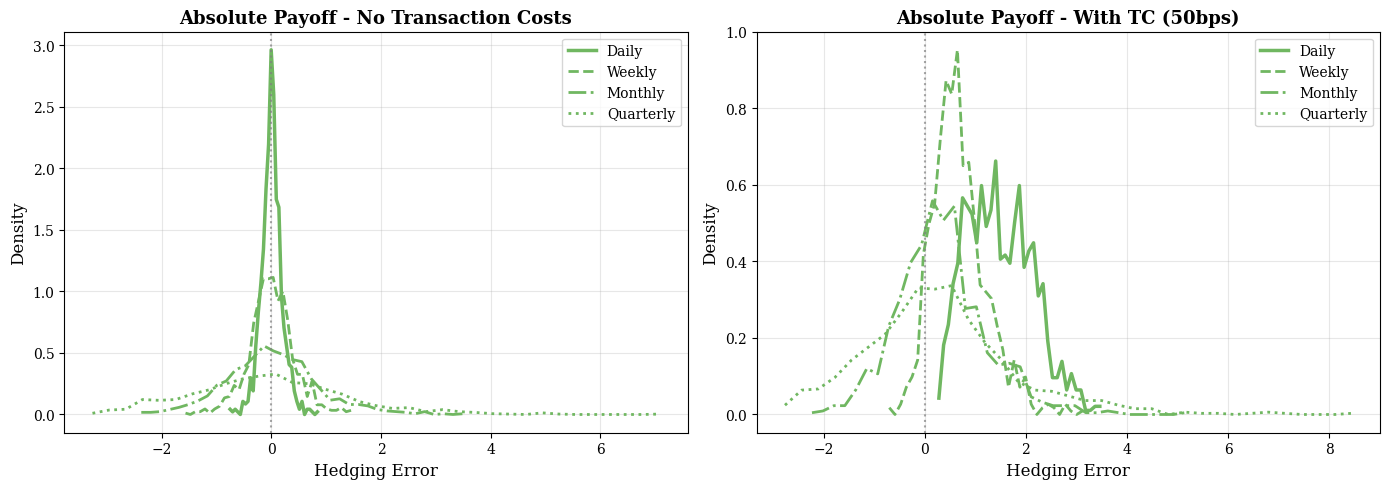

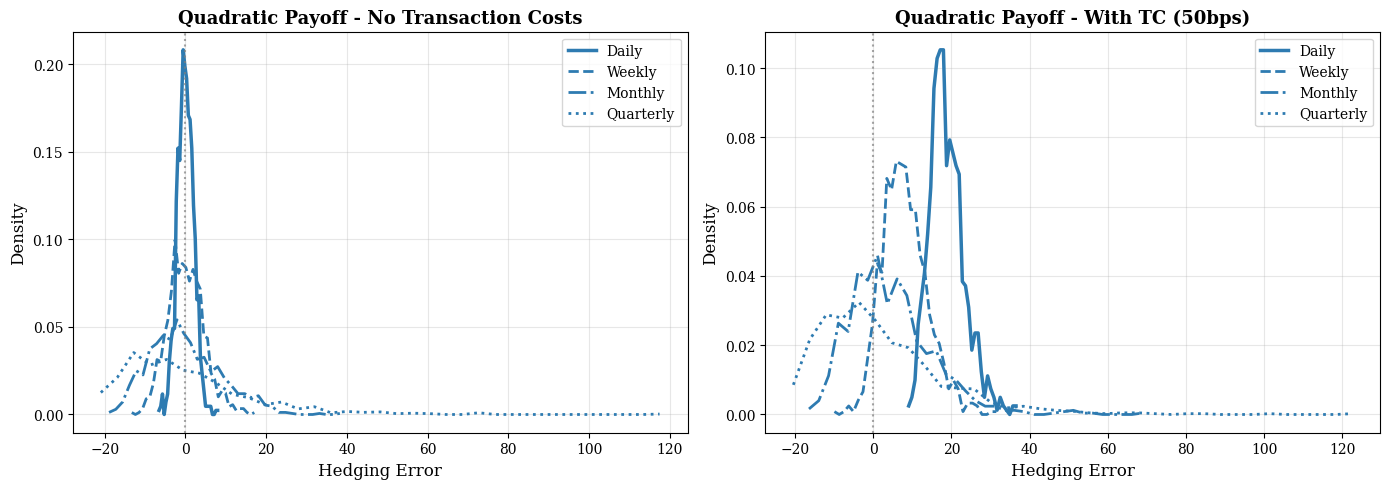

In [22]:
# ============================================================================
# PLOT: Hedging Error Distributions (Frontiers) - No TC vs With TC
# ============================================================================

interval_styles = {
    'Daily': ('-', 2.5),
    'Weekly': ('--', 2.0),
    'Monthly': ('-.', 2.0),
    'Quarterly': (':', 2.0)
}

# === FIGURE 1: Absolute Payoff - No TC vs With TC ===
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: No TC
ax = axes[0]
for label in rebalancing_intervals.keys():
    errors = errors_abs_noTC[label]
    hist, bins = np.histogram(errors, bins=35, density=True)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    linestyle, lw = interval_styles[label]
    ax.plot(bin_centers, hist, color=green, linestyle=linestyle, linewidth=lw, label=label)
ax.axvline(0, color=grey, linestyle=':', linewidth=1.5, alpha=0.7)
ax.set_xlabel('Hedging Error', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.set_title('Absolute Payoff - No Transaction Costs', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)

# Right: With TC
ax = axes[1]
for label in rebalancing_intervals.keys():
    errors = errors_abs_TC[label]
    hist, bins = np.histogram(errors, bins=35, density=True)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    linestyle, lw = interval_styles[label]
    ax.plot(bin_centers, hist, color=green, linestyle=linestyle, linewidth=lw, label=label)
ax.axvline(0, color=grey, linestyle=':', linewidth=1.5, alpha=0.7)
ax.set_xlabel('Hedging Error', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.set_title('Absolute Payoff - With TC (50bps)', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('report/Plots/hedging_errors_abs_frontiers.pdf', dpi=300, bbox_inches='tight')
plt.show()

# === FIGURE 2: Quadratic Payoff - No TC vs With TC ===
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: No TC
ax = axes[0]
for label in rebalancing_intervals.keys():
    errors = errors_quad_noTC[label]
    hist, bins = np.histogram(errors, bins=35, density=True)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    linestyle, lw = interval_styles[label]
    ax.plot(bin_centers, hist, color=blue, linestyle=linestyle, linewidth=lw, label=label)
ax.axvline(0, color=grey, linestyle=':', linewidth=1.5, alpha=0.7)
ax.set_xlabel('Hedging Error', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.set_title('Quadratic Payoff - No Transaction Costs', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)

# Right: With TC
ax = axes[1]
for label in rebalancing_intervals.keys():
    errors = errors_quad_TC[label]
    hist, bins = np.histogram(errors, bins=35, density=True)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    linestyle, lw = interval_styles[label]
    ax.plot(bin_centers, hist, color=blue, linestyle=linestyle, linewidth=lw, label=label)
ax.axvline(0, color=grey, linestyle=':', linewidth=1.5, alpha=0.7)
ax.set_xlabel('Hedging Error', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.set_title('Quadratic Payoff - With TC (50bps)', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('report/Plots/hedging_errors_quad_frontiers.pdf', dpi=300, bbox_inches='tight')
plt.show()


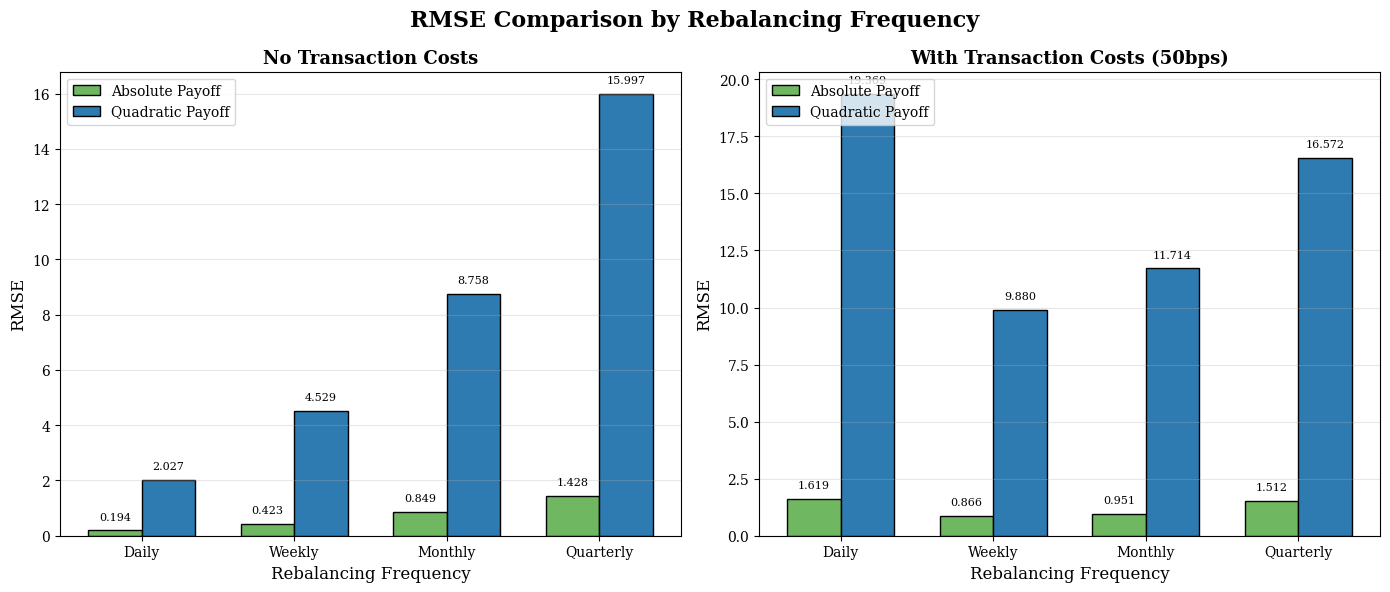

In [23]:

# ============================================================================
# PLOT: RMSE Comparison (Bar Chart)
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

intervals = list(rebalancing_intervals.keys())
x = np.arange(len(intervals))
width = 0.35

# Left: No TC
ax = axes[0]
rmse_abs_noTC = [np.sqrt(np.mean(errors_abs_noTC[label]**2)) for label in intervals]
rmse_quad_noTC = [np.sqrt(np.mean(errors_quad_noTC[label]**2)) for label in intervals]

bars1 = ax.bar(x - width/2, rmse_abs_noTC, width, label='Absolute Payoff', color=green, edgecolor='black', linewidth=1)
bars2 = ax.bar(x + width/2, rmse_quad_noTC, width, label='Quadratic Payoff', color=blue, edgecolor='black', linewidth=1)
ax.set_xlabel('Rebalancing Frequency', fontsize=12)
ax.set_ylabel('RMSE', fontsize=12)
ax.set_title('No Transaction Costs', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(intervals)
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.02*max(rmse_abs_noTC+rmse_quad_noTC),
            f'{height:.3f}', ha='center', va='bottom', fontsize=8)

for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.02*max(rmse_abs_noTC+rmse_quad_noTC),
            f'{height:.3f}', ha='center', va='bottom', fontsize=8)

# Right: With TC
ax = axes[1]
rmse_abs_TC = [np.sqrt(np.mean(errors_abs_TC[label]**2)) for label in intervals]
rmse_quad_TC = [np.sqrt(np.mean(errors_quad_TC[label]**2)) for label in intervals]

bars1 = ax.bar(x - width/2, rmse_abs_TC, width, label='Absolute Payoff', color=green, edgecolor='black', linewidth=1)
bars2 = ax.bar(x + width/2, rmse_quad_TC, width, label='Quadratic Payoff', color=blue, edgecolor='black', linewidth=1)
ax.set_xlabel('Rebalancing Frequency', fontsize=12)
ax.set_ylabel('RMSE', fontsize=12)
ax.set_title('With Transaction Costs (50bps)', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(intervals)
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.02*max(rmse_abs_TC+rmse_quad_TC),
            f'{height:.3f}', ha='center', va='bottom', fontsize=8)

for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.02*max(rmse_abs_TC+rmse_quad_TC),
            f'{height:.3f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('RMSE Comparison by Rebalancing Frequency', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('report/Plots/hedging_rmse_comparison_TC.pdf', dpi=300, bbox_inches='tight')
plt.show()


In [24]:
# ============================================================================
# PRINT SUMMARY STATISTICS
# ============================================================================
print("\n" + "="*80)
print("RMSE SUMMARY")
print("="*80)
print(f"{'Interval':<12} | {'Abs No TC':>12} | {'Quad No TC':>12} | {'Abs TC':>12} | {'Quad TC':>12}")
print("-"*80)
for i, label in enumerate(intervals):
    print(f"{label:<12} | {rmse_abs_noTC[i]:>12.4f} | {rmse_quad_noTC[i]:>12.4f} | {rmse_abs_TC[i]:>12.4f} | {rmse_quad_TC[i]:>12.4f}")
print("="*80)


RMSE SUMMARY
Interval     |    Abs No TC |   Quad No TC |       Abs TC |      Quad TC
--------------------------------------------------------------------------------
Daily        |       0.1936 |       2.0268 |       1.6195 |      19.3693
Weekly       |       0.4227 |       4.5286 |       0.8659 |       9.8801
Monthly      |       0.8488 |       8.7583 |       0.9512 |      11.7138
Quarterly    |       1.4284 |      15.9965 |       1.5119 |      16.5715


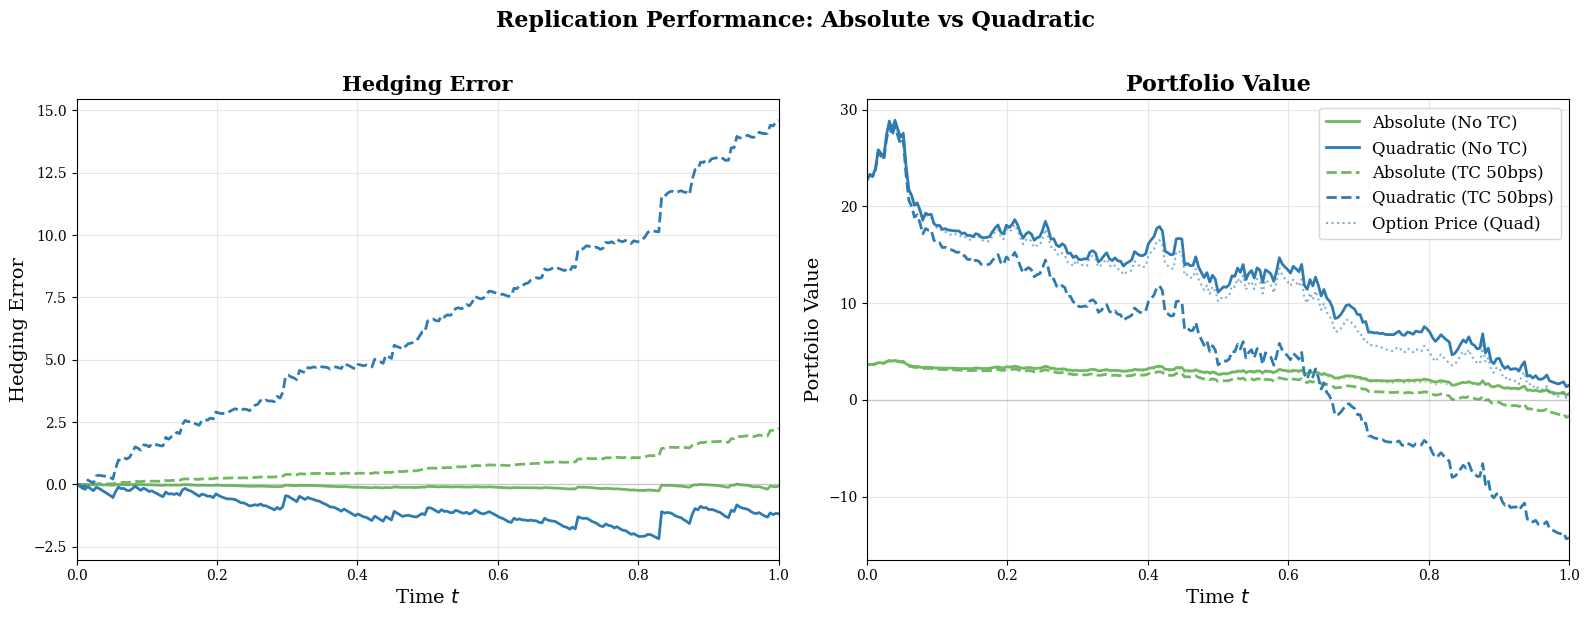


PORTFOLIO VALUE SUMMARY

Absolute Payoff:
  Final Portfolio (No TC):  0.6691
  Final Portfolio (TC):     -1.6454
  Final Option Price:        0.5995
  Error (No TC):            -0.0697
  Error (TC):               2.2449

Quadratic Payoff:
  Final Portfolio (No TC):  1.5396
  Final Portfolio (TC):     -14.2478
  Final Option Price:        0.3594
  Error (No TC):            -1.1802
  Error (TC):               14.6072


In [25]:
# ============================================================================
# PORTFOLIO VALUE AND HEDGING ERROR COMPARISON (Both Products, Side by Side)
# ============================================================================
c = 0.005

# === Run simulations with and without TC ===
np.random.seed(42)
S_path = simulate_one_path(S0, r, sigma, T, dt)

# Absolute Payoff
t_abs, V_abs_noTC, port_abs_noTC, _, _, _ = delta_hedge_abs_TC(S_path, K, r, sigma, T, dt, 0.0)
t_abs, V_abs_TC, port_abs_TC, _, _, _ = delta_hedge_abs_TC(S_path, K, r, sigma, T, dt, c)

# Quadratic Payoff
t_quad, V_quad_noTC, port_quad_noTC, _, _, _ = delta_hedge_quad_TC(S_path, K, r, sigma, T, dt, 0.0)
t_quad, V_quad_TC, port_quad_TC, _, _, _ = delta_hedge_quad_TC(S_path, K, r, sigma, T, dt, c)

# === PLOT: Side by Side (Hedging Error & Portfolio Value) ===
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Hedging Error ---
ax = axes[0]

# No TC
ax.plot(t_abs, V_abs_noTC - port_abs_noTC, color=green, linewidth=2, label='Absolute (No TC)')
ax.plot(t_quad, V_quad_noTC - port_quad_noTC, color=blue, linewidth=2, label='Quadratic (No TC)')

# With TC
ax.plot(t_abs, V_abs_TC - port_abs_TC, color=green, linestyle='--', linewidth=2, label='Absolute (TC 50bps)')
ax.plot(t_quad, V_quad_TC - port_quad_TC, color=blue, linestyle='--', linewidth=2, label='Quadratic (TC 50bps)')

ax.axhline(0, color='grey', linestyle='-', alpha=0.3, linewidth=1)
ax.set_xlabel('Time $t$', fontsize=14)
ax.set_ylabel('Hedging Error', fontsize=14)
ax.set_title('Hedging Error', fontsize=15, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.set_xlim(0, T)

# --- Plot 2: Portfolio Value ---
ax = axes[1]

# No TC
ax.plot(t_abs, port_abs_noTC, color=green, linewidth=2, label='Absolute (No TC)')
ax.plot(t_quad, port_quad_noTC, color=blue, linewidth=2, label='Quadratic (No TC)')

# With TC
ax.plot(t_abs, port_abs_TC, color=green, linestyle='--', linewidth=2, label='Absolute (TC 50bps)')
ax.plot(t_quad, port_quad_TC, color=blue, linestyle='--', linewidth=2, label='Quadratic (TC 50bps)')

# Option prices (reference)
ax.plot(t_abs, V_abs_noTC, color=green, linestyle=':', linewidth=1.5, alpha=0.6)
ax.plot(t_quad, V_quad_noTC, color=blue, linestyle=':', linewidth=1.5, alpha=0.6, label='Option Price (Quad)')

ax.axhline(0, color='grey', linestyle='-', alpha=0.3, linewidth=1)
ax.set_xlabel('Time $t$', fontsize=14)
ax.set_ylabel('Portfolio Value', fontsize=14)
ax.set_title('Portfolio Value', fontsize=16, fontweight='bold')
ax.legend(loc='upper right', fontsize=12)
ax.grid(True, alpha=0.3)
ax.set_xlim(0, T)

plt.suptitle('Replication Performance: Absolute vs Quadratic', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('report/Plots/replication_performance_side_by_side.pdf', dpi=300, bbox_inches='tight')
plt.show()

# === Print Summary ===
print("\n" + "="*70)
print("PORTFOLIO VALUE SUMMARY")
print("="*70)
print(f"\nAbsolute Payoff:")
print(f"  Final Portfolio (No TC):  {port_abs_noTC[-1]:.4f}")
print(f"  Final Portfolio (TC):     {port_abs_TC[-1]:.4f}")
print(f"  Final Option Price:        {V_abs_noTC[-1]:.4f}")
print(f"  Error (No TC):            {V_abs_noTC[-1] - port_abs_noTC[-1]:.4f}")
print(f"  Error (TC):               {V_abs_TC[-1] - port_abs_TC[-1]:.4f}")

print(f"\nQuadratic Payoff:")
print(f"  Final Portfolio (No TC):  {port_quad_noTC[-1]:.4f}")
print(f"  Final Portfolio (TC):     {port_quad_TC[-1]:.4f}")
print(f"  Final Option Price:        {V_quad_noTC[-1]:.4f}")
print(f"  Error (No TC):            {V_quad_noTC[-1] - port_quad_noTC[-1]:.4f}")
print(f"  Error (TC):               {V_quad_TC[-1] - port_quad_TC[-1]:.4f}")
print("="*70)